# Predicting Hospital Length of Stay at Admission

**A revised, individual follow-up study by Shuyuan Wang**, building on the TUM *Programming* group project (Group 2: Shuyuan Wang, Luoze Guo, Beibei Le, Ping-Jui Chen, Chia-Chen Li). The original group submission is kept unchanged in [`../original_course_project/`](../original_course_project/). What changed and why is documented in [`../PROJECT_EVOLUTION.md`](../PROJECT_EVOLUTION.md); the written summary of this study is [`../FINAL_REPORT.md`](../FINAL_REPORT.md).

This notebook is the main reading entry of the revised project. Every step that matters for the results (cleaning, splitting, preprocessing, training, prediction, evaluation, simulation) is written out in the cells below. The only external helper is `src/plotting.py`, which draws charts from numbers computed here.

**How to read it.** Each section starts with *why* the step is needed and ends with *how to read the output*. Numbers quoted in the text come from the run whose outputs are saved in this notebook (and in `../results/`).

Contents
1. Business context and research questions
2. Data source, fields and target definition
3. Data quality checks and cleaning
4. Exploratory analysis
5. Feature selection and information availability
6. Train / validation / test design
7. Baselines
8. Model training and selection (validation set only)
9. Final test evaluation
10. Interpretation and error analysis
11. Operational use: simulated scenarios
12. Conclusions, business implications and limitations

In [1]:
# ---------------------------------------------------------------
# Setup: imports, paths, run mode and the results container
# ---------------------------------------------------------------
import os
import sys
import json
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, log_loss,
                             precision_recall_fscore_support, confusion_matrix,
                             roc_auc_score, average_precision_score, brier_score_loss)
from sklearn.inspection import permutation_importance

# The notebook lives in notebooks/; the project root is one level up.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import plotting  # chart helpers only

# QUICK mode (set by `python main.py --quick`) runs a small version for testing.
# It writes to results_quick/ so it can never overwrite the official results.
QUICK = os.environ.get("LOS_QUICK", "0") == "1"
RESULTS_DIR = PROJECT_ROOT / ("results_quick" if QUICK else "results")
FIG_DIR = RESULTS_DIR / "figures"
TABLE_DIR = RESULTS_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
plotting.FIG_DIR = FIG_DIR

SEED = 42  # one seed for every random step, so the run is reproducible

# Compute budget. QUICK mode only shrinks these numbers; the method is identical.
SETTINGS = {
    "patient_sample_fraction": 0.25 if QUICK else 1.0,
    "hgb_max_iter": 150 if QUICK else 500,
    "hgb_max_iter_11bin": 120 if QUICK else 400,
    "rf_n_estimators": 60 if QUICK else 200,
    "bootstrap_reps": 50 if QUICK else 300,
    "mc_draws": 300 if QUICK else 2000,
    "importance_rows": 5000 if QUICK else 20000,
    "importance_repeats": 2 if QUICK else 5,
}

RESULTS = {"quick_mode": QUICK, "settings": SETTINGS}  # all reported numbers end up here
RUN_START = time.time()


def save_table(table, name):
    """Save a result table as CSV in results/tables and return it for display."""
    table.to_csv(TABLE_DIR / (name + ".csv"))
    return table


pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
print("Python", platform.python_version(), "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)
print("Mode:", "QUICK (test run)" if QUICK else "FULL", "| results ->", RESULTS_DIR)

Python 3.13.17 | pandas 3.0.5 | scikit-learn 1.9.1 | numpy 2.5.3
Mode: FULL | results -> /home/claude/v2/results


## 1. Business context and research questions

Hospitals plan beds, staff and discharge support under uncertainty. How long a newly admitted patient will stay (*length of stay*, LOS) is one of the main unknowns: a ward that receives many long-stay patients fills up and blocks new admissions, while early knowledge of a likely long stay gives time to arrange rehabilitation places, home care or step-down beds.

The dataset records 318k hospital admissions with LOS grouped into 10-day bins. Following the course brief, we group LOS into three classes: **Short (0-20 days)**, **Medium (21-50 days)** and **Long (more than 50 days)**.

**Research questions**

1. **Prediction.** Using only information that is plausibly available at admission, how well can we classify the LOS class of a *patient the model has never seen*, compared with simple baselines?
2. **Drivers.** Which admission characteristics are associated with longer stays?
3. **Operational use.** In simulated scenarios, how useful are the predictions for (a) estimating the total bed-days a group of admissions will need, and (b) screening admissions for likely long stays?

The target user is a hospital planning team, so the evaluation focuses on new patients and on the two planning tasks above, not only on overall accuracy.

## 2. Data source, fields and target definition

The file is the course dataset (`Topic3_healthcare_analytics_dataset`), the same data as the public *AV Healthcare Analytics II* dataset. Each row is one admission (`case_id`) of one patient (`patientid`) to one of 32 hospitals.

In [2]:
DATA_PATH = PROJECT_ROOT / "data" / "healthcare_analytics.csv"
raw = pd.read_csv(DATA_PATH, low_memory=False)
raw.columns = raw.columns.str.strip()  # some column names carry stray spaces
print("Rows:", len(raw), "| columns:", raw.shape[1])
raw.head()

Rows: 455495 | columns: 18


,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,patientid,City_Code_Patient,Type of Admission,Severity of Illness,Visitors with Patient,Age,Admission_Deposit,Stay
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911.0,0-10
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954.0,41-50
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745.0,31-40
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272.0,41-50
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558.0,41-50


**Field dictionary.** The last column records whether each field can be used for a prediction made *at admission*. The dataset has no documentation of when each field is recorded, so these are stated assumptions (see Section 5).

In [3]:
field_dictionary = pd.DataFrame([
    ("case_id", "Admission identifier", "ID", "Not a feature"),
    ("Hospital_code", "Hospital (32 hospitals)", "Categorical", "Yes"),
    ("Hospital_type_code", "Hospital type (a-g)", "Categorical", "Yes"),
    ("City_Code_Hospital", "City of the hospital", "Categorical", "Yes"),
    ("Hospital_region_code", "Region of the hospital (X/Y/Z)", "Categorical", "Yes"),
    ("Available Extra Rooms in Hospital", "Free rooms in the hospital", "Numeric", "Yes (assumed snapshot at admission)"),
    ("Department", "Treating department", "Categorical", "Yes (assumed assigned at admission)"),
    ("Ward_Type", "Ward type (P-U)", "Categorical", "Yes (assumed admission ward)"),
    ("Ward_Facility_Code", "Ward facility (A-F)", "Categorical", "Yes"),
    ("Bed Grade", "Condition of the bed (1-4)", "Ordinal", "Yes (assumed)"),
    ("patientid", "Patient identifier", "ID", "Not a feature; used to group the split"),
    ("City_Code_Patient", "City where the patient lives", "Categorical", "Yes"),
    ("Type of Admission", "Trauma / Emergency / Urgent", "Categorical", "Yes"),
    ("Severity of Illness", "Minor / Moderate / Extreme", "Ordinal", "Yes (assumed assessed at admission)"),
    ("Visitors with Patient", "Number of visitors with the patient", "Count", "UNCLEAR (may be recorded during the stay)"),
    ("Age", "Age band (0-10 ... 91-100)", "Ordinal", "Yes"),
    ("Admission_Deposit", "Deposit paid at admission", "Numeric", "Yes"),
    ("Stay", "Length of stay, 11 bins of 10 days", "Target", "Outcome"),
], columns=["field", "meaning", "type", "available at admission?"]).set_index("field")
save_table(field_dictionary, "field_dictionary")
field_dictionary

,meaning,type,available at admission?
field,,,
case_id,Admission identifier,ID,Not a feature
Hospital_code,Hospital (32 hospitals),Categorical,Yes
Hospital_type_code,Hospital type (a-g),Categorical,Yes
City_Code_Hospital,City of the hospital,Categorical,Yes
Hospital_region_code,Region of the hospital (X/Y/Z),Categorical,Yes
Available Extra Rooms in Hospital,Free rooms in the hospital,Numeric,Yes (assumed snapshot at admission)
Department,Treating department,Categorical,Yes (assumed assigned at admission)
Ward_Type,Ward type (P-U),Categorical,Yes (assumed admission ward)
Ward_Facility_Code,Ward facility (A-F),Categorical,Yes


**Target definition.** `Stay` has 11 ordered bins. We use two versions of the target:

* `los_class` (main target): Short = 0-20 days (bins 0-1), Medium = 21-50 days (bins 2-4), Long = more than 50 days (bins 5-10).
* `stay_bin` (0-10): used only in Section 11, where we need a full distribution over days to estimate bed-days.

Bed-days need a number of days, but the data only give a 10-day range. We therefore use the **bin midpoint as a proxy** (5, 15, ..., 95 days) and assume **110 days** for "More than 100 Days". This is an assumption, not a measurement; Section 11.6 tests how much it matters.

In [4]:
STAY_BINS = ["0-10", "11-20", "21-30", "31-40", "41-50", "51-60",
             "61-70", "71-80", "81-90", "91-100", "More than 100 Days"]
BIN_INDEX = {label: i for i, label in enumerate(STAY_BINS)}
CLASS_OF_BIN = np.array([0, 0, 1, 1, 1, 2, 2, 2, 2, 2, 2])   # 0 Short, 1 Medium, 2 Long
PROXY_DAYS = np.array([5, 15, 25, 35, 45, 55, 65, 75, 85, 95, 110], dtype=float)
CLASS_NAMES = ["Short", "Medium", "Long"]
AGE_BANDS = ["0-10", "11-20", "21-30", "31-40", "41-50",
             "51-60", "61-70", "71-80", "81-90", "91-100"]

## 3. Data quality checks and cleaning

Before modelling we check missing values, unlabeled rows, duplicates, value ranges and whether some columns are just properties of the hospital. Cleaning here is limited to **deterministic** recoding (the same rule applied to every row). Anything that is *learned from data*, such as the median used to fill a missing value, is learned later from the training set only (Section 6).

In [5]:
# 3.1 Missing values in the raw file
missing = raw.isna().sum()
missing = missing[missing > 0].to_frame("missing rows")
missing["% of rows"] = (missing["missing rows"] / len(raw) * 100).round(2)
missing

,missing rows,% of rows
Bed Grade,148,0.03
City_Code_Patient,6689,1.47
Stay,137057,30.09


In [6]:
# 3.2 Rows without a Stay label: who are they?
labeled_mask = raw["Stay"].notna()
labeled_patients = set(raw.loc[labeled_mask, "patientid"])
unlabeled_patients = set(raw.loc[~labeled_mask, "patientid"])
print("Labeled admissions:  ", int(labeled_mask.sum()))
print("Unlabeled admissions:", int((~labeled_mask).sum()))
print("Patients appearing in both groups:", len(labeled_patients & unlabeled_patients))
RESULTS["data"] = {
    "rows_in_file": int(len(raw)),
    "labeled_rows": int(labeled_mask.sum()),
    "unlabeled_rows": int((~labeled_mask).sum()),
    "labeled_patients": int(len(labeled_patients)),
    "patients_in_both": int(len(labeled_patients & unlabeled_patients)),
}

Labeled admissions:   318438
Unlabeled admissions: 137057
Patients appearing in both groups: 0


**How to read this.** 137,057 admissions have no `Stay` value, and none of their patients appear among the labeled admissions (they look like a separate held-out set of the original competition). Without a label they can be used neither for training nor for evaluation, so they are **excluded from the whole analysis**. We do not use them to build features either.

In [7]:
# 3.3 Work on the labeled admissions only
lab_raw = raw[labeled_mask].reset_index(drop=True)

# Duplicates: identical rows apart from the admission id
dup_all = lab_raw.drop(columns="case_id").duplicated(keep=False)    # every row that has a twin
dup_extra = lab_raw.drop(columns="case_id").duplicated(keep="first")  # the extra copies only
print("Rows with an identical twin (apart from case_id):", int(dup_all.sum()),
      "| extra copies:", int(dup_extra.sum()),
      "| patients involved:", lab_raw.loc[dup_all, "patientid"].nunique())
RESULTS["data"]["duplicate_rows_with_twin"] = int(dup_all.sum())
RESULTS["data"]["duplicate_extra_copies"] = int(dup_extra.sum())

# Columns that never change within a hospital are hospital properties
hospital_level = ["Hospital_type_code", "City_Code_Hospital", "Hospital_region_code", "Ward_Facility_Code"]
print("Max distinct values per hospital:")
print(lab_raw.groupby("Hospital_code")[hospital_level].nunique().max().to_string())

# Value ranges of numeric columns
lab_raw[["Available Extra Rooms in Hospital", "Bed Grade", "Visitors with Patient",
         "Admission_Deposit"]].describe().round(1)

Rows with an identical twin (apart from case_id): 124 | extra copies: 65 | patients involved: 55
Max distinct values per hospital:
Hospital_type_code      1
City_Code_Hospital      1
Hospital_region_code    1
Ward_Facility_Code      1


,Available Extra Rooms in Hospital,Bed Grade,Visitors with Patient,Admission_Deposit
count,318438.0,318325.0,318438.0,318438.0
mean,3.2,2.6,3.3,4880.7
std,1.2,0.9,1.8,1086.8
min,0.0,1.0,0.0,1800.0
25%,2.0,2.0,2.0,4186.0
50%,3.0,3.0,3.0,4741.0
75%,4.0,3.0,4.0,5409.0
max,24.0,4.0,32.0,11008.0


**How to read this.**
* 124 rows have an identical twin apart from `case_id` (65 extra copies, 55 patients). Each twin belongs to the same patient, so duplicates never cross the patient-grouped split. They may be genuine repeat admissions with identical records; we keep them.
* Hospital type, city, region and ward facility are fixed for each hospital, so they add no information beyond `Hospital_code` itself. We keep them because they let a tree model group similar hospitals, and the redundancy does no harm to the models used here.
* Value ranges look plausible (deposits 1,800-11,008; up to 24 free rooms; up to 32 visitors). Tree models are not affected by extreme values, and the linear model standardises its inputs, so no clipping is applied.
* `Bed Grade` is missing in 113 labeled rows (filled later with the training median). `City_Code_Patient` is missing in about 4.5k rows; we keep "Missing" as its own category, because it may itself carry information.

In [8]:
# 3.4 Deterministic cleaning and recoding (no statistics learned from data)
df = lab_raw.copy()

# Targets
df["stay_bin"] = df["Stay"].map(BIN_INDEX).astype(int)
df["los_class"] = CLASS_OF_BIN[df["stay_bin"].to_numpy()]
df["is_long"] = (df["los_class"] == 2).astype(int)
df["proxy_days"] = PROXY_DAYS[df["stay_bin"].to_numpy()]

# Ordered categories become ordered integers
df["Severity of Illness"] = df["Severity of Illness"].map({"Minor": 0, "Moderate": 1, "Extreme": 2}).astype(int)
df["Age"] = df["Age"].map({band: i for i, band in enumerate(AGE_BANDS)}).astype(int)  # 0 = 0-10, ..., 9 = 91-100

# Nominal codes are stored as text so that no model treats e.g. hospital 26 as "bigger" than hospital 2
df["City_Code_Patient"] = df["City_Code_Patient"].map(lambda v: "Missing" if pd.isna(v) else str(int(v)))
for col in ["Hospital_code", "City_Code_Hospital"]:
    df[col] = df[col].astype(int).astype(str)
for col in ["Hospital_type_code", "Hospital_region_code", "Department", "Ward_Type",
            "Ward_Facility_Code", "Type of Admission"]:
    df[col] = df[col].astype(str)

# QUICK mode only: keep a random 25% of patients (whole patients, so groups stay intact)
if SETTINGS["patient_sample_fraction"] < 1.0:
    rng_quick = np.random.default_rng(SEED)
    all_patients = df["patientid"].unique()
    kept = rng_quick.choice(all_patients, size=int(len(all_patients) * SETTINGS["patient_sample_fraction"]), replace=False)
    df = df[df["patientid"].isin(kept)].reset_index(drop=True)

print("Admissions used:", len(df), "| patients:", df["patientid"].nunique(),
      "| admissions per patient:", round(len(df) / df["patientid"].nunique(), 2))
RESULTS["data"]["analysis_rows"] = int(len(df))
RESULTS["data"]["analysis_patients"] = int(df["patientid"].nunique())
df[["case_id", "patientid", "Hospital_code", "Ward_Type", "Severity of Illness", "Age",
    "Stay", "stay_bin", "los_class", "proxy_days"]].head()

Admissions used: 318438 | patients: 92017 | admissions per patient: 3.46


,case_id,patientid,Hospital_code,Ward_Type,Severity of Illness,Age,Stay,stay_bin,los_class,proxy_days
0,1,31397,8,R,2,5,0-10,0,0,5.0
1,2,31397,2,S,2,5,41-50,4,1,45.0
2,3,31397,10,S,2,5,31-40,3,1,35.0
3,4,31397,26,R,2,5,41-50,4,1,45.0
4,5,31397,26,S,2,5,41-50,4,1,45.0


## 4. Exploratory analysis

EDA here is descriptive: it shows how LOS is distributed and which admission characteristics go together with long stays. It is not used to tune any model. Feature choices in Section 5 are based on *when information is available*, not on these plots.

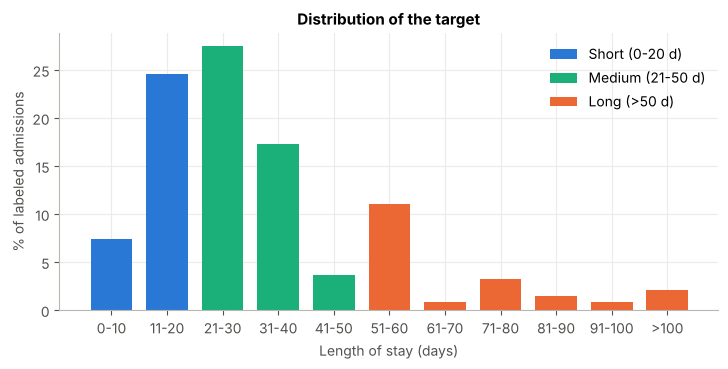

,share of admissions
Short,0.320
Medium,0.485
Long,0.196


In [9]:
# 4.1 Target distribution
bin_share = df["stay_bin"].value_counts(normalize=True).sort_index()
labels = [b.replace("More than 100 Days", ">100") for b in STAY_BINS]
fig = plotting.stay_distribution(bin_share.values, labels, CLASS_OF_BIN)
plotting.save_show(fig, "01_target_distribution")

class_share = df["los_class"].value_counts(normalize=True).sort_index()
class_share.index = CLASS_NAMES
RESULTS["data"]["class_share"] = {k: round(float(v), 4) for k, v in class_share.items()}
class_share.round(3).to_frame("share of admissions")

**How to read this.** Medium stays are the largest class (about 48%), Short about 32% and Long about 20%. The classes are moderately imbalanced, so accuracy alone can hide poor performance on the smaller classes; we will also report macro-F1 (the unweighted mean of the three per-class F1 scores) and per-class recall. Within "Long", the 51-60 day bin dominates.

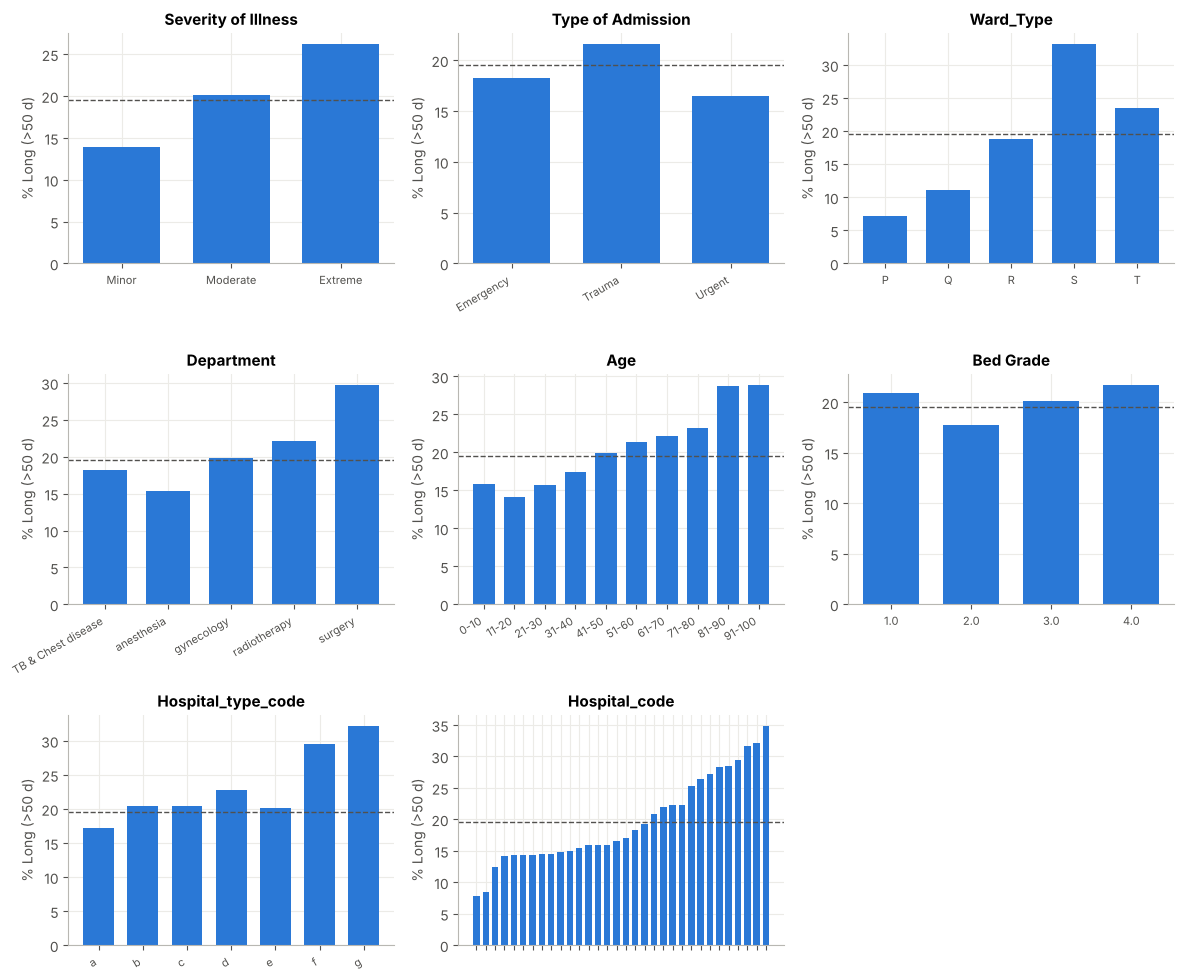

,levels (n>=200),lowest Long share,highest Long share,spread (pp)
feature,,,,
Hospital_code,32,0.077,0.348,27.1
Ward_Type,5,0.071,0.332,26.0
Hospital_type_code,7,0.172,0.322,15.0
Age,10,0.141,0.289,14.7
Department,5,0.153,0.297,14.4
Severity of Illness,3,0.139,0.262,12.3
Type of Admission,3,0.165,0.216,5.1
Bed Grade,4,0.178,0.217,3.9


In [10]:
# 4.2 Share of Long stays across the levels of each admission characteristic
overall_long = df["is_long"].mean()
panel_specs = [
    ("Severity of Illness", ["Minor", "Moderate", "Extreme"]),
    ("Type of Admission", None),
    ("Ward_Type", None),
    ("Department", None),
    ("Age", AGE_BANDS),
    ("Bed Grade", None),
    ("Hospital_type_code", None),
    ("Hospital_code", None),
]
panels = []
spread_rows = []
for col, names in panel_specs:
    stats = df.groupby(col)["is_long"].agg(["mean", "size"])
    stats = stats[stats["size"] >= 200]          # ignore tiny groups (e.g. ward U has 9 rows)
    if col == "Hospital_code":
        stats = stats.sort_values("mean")
    level_labels = [names[int(i)] for i in stats.index] if names else [str(i) for i in stats.index]
    if col == "Hospital_code":
        level_labels = ["" for _ in level_labels]   # 32 hospitals: show the spread, not the codes
    panels.append((col, level_labels, stats["mean"].values))
    spread_rows.append((col, len(stats), stats["mean"].min(), stats["mean"].max()))

fig = plotting.long_share_panels(panels, overall_long)
plotting.save_show(fig, "02_long_share_by_feature")

spread = pd.DataFrame(spread_rows, columns=["feature", "levels (n>=200)", "lowest Long share", "highest Long share"])
spread["spread (pp)"] = ((spread["highest Long share"] - spread["lowest Long share"]) * 100).round(1)
spread = spread.sort_values("spread (pp)", ascending=False).set_index("feature")
save_table(spread.round(3), "eda_long_share_spread")
spread.round(3)

**How to read this.** Each panel shows the share of Long stays for each level; the dashed line is the overall share (about 20%). The table summarises each panel by its spread (highest minus lowest share). **Hospital and ward type separate patients most strongly** (Long share from about 8% to 35% across hospitals and from 7% to 33% across wards). Hospital type, age, department and severity follow with spreads of 12-15 points, with the Long share rising steadily with severity and, with small exceptions, with age. Admission type and bed grade matter least. These are single-variable associations, not causal effects: ward type and severity, for example, are related to each other.

In [11]:
# 4.3 Admission deposit and the LOS class (numeric feature)
deposit_by_class = df.groupby("los_class")["Admission_Deposit"].describe()[["25%", "50%", "75%", "mean"]]
deposit_by_class.index = CLASS_NAMES
deposit_by_class.round(0)

,25%,50%,75%,mean
Short,4208.0,4741.0,5375.0,4858.0
Medium,4287.0,4821.0,5472.0,4960.0
Long,3929.0,4502.0,5271.0,4722.0


**How to read this.** Long stays have slightly lower deposits (median about 4,500 against 4,700-4,800), but the three distributions overlap almost completely, so on its own the deposit tells little about LOS. (Section 10.1 shows that it still helps the model in combination with hospital and ward, where deposit levels differ.)

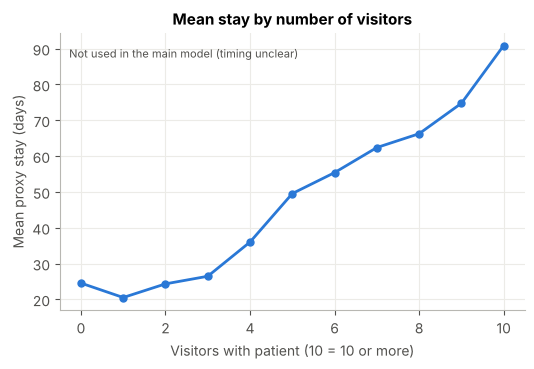

Pearson correlation between visitors and LOS class: 0.417


In [12]:
# 4.4 Visitors with Patient: strong association, but unclear timing
visitors_mean_days = df.groupby(df["Visitors with Patient"].clip(upper=10))["proxy_days"].mean()
fig = plotting.line_by_value(visitors_mean_days.index, visitors_mean_days.values,
                             "Mean stay by number of visitors", "Visitors with patient (10 = 10 or more)",
                             "Mean proxy stay (days)", note="Not used in the main model (timing unclear)")
plotting.save_show(fig, "03_visitors_vs_stay")
corr_visitors = float(np.corrcoef(df["Visitors with Patient"], df["los_class"])[0, 1])
print("Pearson correlation between visitors and LOS class: %.3f" % corr_visitors)
RESULTS["eda"] = {"corr_visitors_los_class": round(corr_visitors, 3)}

**How to read this.** More visitors go together with much longer stays (correlation about +0.42). The original project reported this correlation as negative; the sign was wrong. The *strength* of the relationship is also a warning sign: if visitors are counted over the stay, a long stay naturally accumulates more visitors, and the variable partly *reflects* the outcome instead of predicting it. Because we cannot tell when it is recorded, the main model excludes it and Section 9.4 measures its effect separately.

In [13]:
# 4.5 Do admissions of the same patient resemble each other?
# For patients with at least two admissions, compare the LOS bins of their first two records.
multi = df[df.groupby("patientid")["case_id"].transform("size") >= 2].sort_values(["patientid", "case_id"])
first_two = multi.groupby("patientid").head(2).copy()
first_two["order"] = first_two.groupby("patientid").cumcount()
pairs = first_two.pivot(index="patientid", columns="order", values="stay_bin")
same_patient_corr = float(pairs[0].corr(pairs[1]))

# Reference: two admissions of *different* patients, paired at random
rng_eda = np.random.default_rng(SEED)
shuffled = rng_eda.permutation(pairs[1].to_numpy())
random_pair_corr = float(np.corrcoef(pairs[0].to_numpy(), shuffled)[0, 1])
print("Patients with 2+ admissions:", len(pairs))
print("LOS correlation, two admissions of the same patient: %.3f" % same_patient_corr)
print("LOS correlation, randomly paired admissions:         %.3f" % random_pair_corr)
RESULTS["eda"]["same_patient_los_corr"] = round(same_patient_corr, 3)
RESULTS["eda"]["random_pair_los_corr"] = round(random_pair_corr, 3)
RESULTS["eda"]["share_patients_multiple_admissions"] = round(float((df.groupby("patientid").size() >= 2).mean()), 3)

Patients with 2+ admissions: 71668
LOS correlation, two admissions of the same patient: 0.316
LOS correlation, randomly paired admissions:         0.000


**How to read this.** Admissions of the same patient have more similar stays than random pairs of admissions. If the same patient appeared in both training and test data, a model could partly *recognise the patient* instead of learning patterns that transfer to new patients, and the test score would be too optimistic. This is why Section 6 splits by patient.

## 5. Feature selection and information availability

A model used at admission can only use information that exists at admission. **"The feature does not use the target label" is not the same as "the feature does not leak information".** Two kinds of features are excluded from the main analysis for this reason:

1. **`Visitors with Patient`**: its recording time is unknown, and it may be counted during the stay. It is excluded from the main model and tested in a supplementary comparison (Section 9.4). Any feature derived from it follows the same rule.
2. **Patient aggregates across admissions** (number of admissions of the patient, the patient's average severity or deposit, and so on). The data have no admission dates and `case_id` is not in time order, so these aggregates mix past and *future* admissions. They are not "history" and are excluded from the main analysis; Section 9.4 reports them as a clearly labeled *retrospective* experiment.

The remaining 14 fields are used. Their availability at admission is an **assumption** we cannot verify from the data: we assume that department, ward type and bed grade refer to the assignment at admission, that severity is assessed at admission, and that "available extra rooms" is a snapshot taken at admission. `patientid` is never a model input; it is used only to keep each patient within a single split.

In [14]:
MAIN_CATEGORICAL = ["Hospital_code", "Hospital_type_code", "City_Code_Hospital", "Hospital_region_code",
                    "Department", "Ward_Type", "Ward_Facility_Code", "Type of Admission", "City_Code_Patient"]
MAIN_NUMERIC = ["Available Extra Rooms in Hospital", "Bed Grade", "Severity of Illness", "Age", "Admission_Deposit"]
FEATURES = MAIN_CATEGORICAL + MAIN_NUMERIC

feature_table = pd.DataFrame({
    "used in main model": ["yes"] * len(FEATURES) + ["no", "no", "no", "no"],
    "role / reason": (["categorical"] * len(MAIN_CATEGORICAL) + ["numeric or ordinal"] * len(MAIN_NUMERIC)
                      + ["identifier", "identifier (grouping only)", "timing unclear -> supplementary only",
                         "outcome"]),
}, index=FEATURES + ["case_id", "patientid", "Visitors with Patient", "Stay"])
print("Main model uses %d features." % len(FEATURES))
feature_table

Main model uses 14 features.


,used in main model,role / reason
Hospital_code,yes,categorical
Hospital_type_code,yes,categorical
City_Code_Hospital,yes,categorical
Hospital_region_code,yes,categorical
Department,yes,categorical
Ward_Type,yes,categorical
Ward_Facility_Code,yes,categorical
Type of Admission,yes,categorical
City_Code_Patient,yes,categorical
Available Extra Rooms in Hospital,yes,numeric or ordinal


## 6. Train / validation / test design

**Goal of the evaluation:** estimate performance on *patients the model has never seen*. All three sets are therefore split **by `patientid`**: every admission of a patient lands in exactly one set.

* **Training set (about 60% of patients):** used to fit models and every learned preprocessing step (category codes, the median for missing `Bed Grade`, scaling for the linear model).
* **Validation set (about 20%):** used to choose models, hyper-parameters and the number of boosting iterations ("early stopping"). Nothing in the validation set is used to fit the models.
* **Test set (about 20%):** touched only once the whole design is frozen (Section 9). It is not used to choose anything.

`GroupShuffleSplit` draws a random share of *patients* (not rows), so the row shares are close to, but not exactly, 60/20/20.

In [15]:
# First set aside 20% of patients as the test set ...
outer_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, test_idx = next(outer_split.split(df, groups=df["patientid"]))
# ... then split the remaining patients 75/25 into training and validation (= 60/20 of all patients)
dev_groups = df["patientid"].to_numpy()[dev_idx]
inner_split = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_pos, val_pos = next(inner_split.split(dev_idx, groups=dev_groups))
train_idx, val_idx = dev_idx[train_pos], dev_idx[val_pos]

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = df.iloc[val_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

# Safety check: no patient may appear in two sets
p_train, p_val, p_test = set(train_df["patientid"]), set(val_df["patientid"]), set(test_df["patientid"])
assert not (p_train & p_val) and not (p_train & p_test) and not (p_val & p_test)

split_summary = pd.DataFrame({
    "admissions": [len(train_df), len(val_df), len(test_df)],
    "patients": [len(p_train), len(p_val), len(p_test)],
    "% Short": [(d["los_class"] == 0).mean() * 100 for d in (train_df, val_df, test_df)],
    "% Medium": [(d["los_class"] == 1).mean() * 100 for d in (train_df, val_df, test_df)],
    "% Long": [(d["los_class"] == 2).mean() * 100 for d in (train_df, val_df, test_df)],
}, index=["train", "validation", "test"]).round(1)
RESULTS["split"] = split_summary.reset_index().rename(columns={"index": "set"}).to_dict(orient="records")
save_table(split_summary, "split_summary")
split_summary

,admissions,patients,% Short,% Medium,% Long
train,191474,55209,31.9,48.5,19.6
validation,63459,18404,32.1,48.3,19.7
test,63505,18404,32.0,48.7,19.3


**Preprocessing, learned on the training set only.** Two input formats are needed:

* **Tree models** (random forest, gradient boosting) get each categorical column as integer codes plus the numeric columns, with a missing `Bed Grade` filled by the *training* median. Trees split on thresholds, so they need no scaling. The gradient boosting model is told which columns are categorical, so it can group categories instead of treating codes as numbers.
* **Logistic regression** gets one-hot encoded categories and standardised numeric columns, because a linear model is sensitive to scale and cannot use arbitrary codes.

Both transformers are fitted with `.fit(train)` and only *applied* to validation and test.

In [16]:
def make_tree_preprocessor(categorical, numeric):
    """Integer codes for categories (unknown -> -1) + training-median fill for numbers."""
    return ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical),
        ("num", SimpleImputer(strategy="median"), numeric),
    ])


def make_linear_preprocessor(categorical, numeric):
    """One-hot categories + median fill and standardisation for numbers."""
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
    ])


tree_prep = make_tree_preprocessor(MAIN_CATEGORICAL, MAIN_NUMERIC).fit(train_df[FEATURES])
X_train = tree_prep.transform(train_df[FEATURES])
X_val = tree_prep.transform(val_df[FEATURES])
X_test = tree_prep.transform(test_df[FEATURES])
CAT_IDX = list(range(len(MAIN_CATEGORICAL)))   # categorical columns come first in X

y_train = train_df["los_class"].to_numpy()
y_val = val_df["los_class"].to_numpy()
y_test = test_df["los_class"].to_numpy()

unseen = {name: int((X[:, CAT_IDX] == -1).any(axis=1).sum()) for name, X in [("validation", X_val), ("test", X_test)]}
print("Tree input shape:", X_train.shape, "| rows with a category unseen in training:", unseen)

Tree input shape: (191474, 14) | rows with a category unseen in training: {'validation': 0, 'test': 0}


## 7. Baselines

A model is only useful if it beats simple rules that a planner could apply without machine learning. We use:

1. **Majority class:** always predict the most frequent class in the training data (Medium). Its probabilities are the training class shares.
2. **Lookup table:** for each combination of hospital, ward type and severity, use the class shares observed in the training data (combinations with fewer than 30 training admissions fall back to the overall shares). This mimics "what usually happens to this kind of patient in this ward".
3. **Logistic regression:** a simple, interpretable linear model (Section 8 tunes its regularisation strength).

In [17]:
def evaluate(name, y_true, proba):
    """Standard classification metrics from a probability matrix (prediction = most likely class)."""
    pred = proba.argmax(axis=1)
    p = np.clip(proba, 1e-15, 1.0)
    p = p / p.sum(axis=1, keepdims=True)
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro"),
        "log_loss": log_loss(y_true, p, labels=[0, 1, 2]),
    }


def lookup_table_probabilities(train_frame, target_frame, keys, min_count=30):
    """Class shares per combination of `keys`, learned on the training rows only."""
    onehot = pd.get_dummies(train_frame["los_class"], dtype=float)          # columns 0, 1, 2
    grouped = pd.concat([train_frame[keys], onehot], axis=1).groupby(keys)
    shares = grouped[[0, 1, 2]].mean()[grouped.size() >= min_count]
    merged = target_frame[keys].merge(shares, left_on=keys, right_index=True, how="left")
    proba = merged[[0, 1, 2]].to_numpy(dtype=float, copy=True)
    overall = onehot.mean().to_numpy()
    missing_rows = np.isnan(proba).any(axis=1)
    proba[missing_rows] = overall                                           # fallback for rare combinations
    return proba


LOOKUP_KEYS = ["Hospital_code", "Ward_Type", "Severity of Illness"]

majority = DummyClassifier(strategy="prior").fit(X_train, y_train)
val_proba = {"Majority class": majority.predict_proba(X_val),
             "Lookup table": lookup_table_probabilities(train_df, val_df, LOOKUP_KEYS)}
pd.DataFrame([evaluate(n, y_val, p) for n, p in val_proba.items()]).set_index("model").round(4)

,accuracy,balanced_accuracy,macro_f1,log_loss
model,,,,
Majority class,0.4825,0.3333,0.2170,1.0362
Lookup table,0.5074,0.4037,0.3875,0.9850


**How to read this.** These are validation scores. The majority rule gets about 48% accuracy but a very low macro-F1, because it never predicts Short or Long. The lookup table is the more serious benchmark: any model must clearly beat it to be worth the extra complexity.

## 8. Model training and selection (validation set only)

We compare three model families under the same split, target and features:

| Family | Why it is included | Settings tried |
|---|---|---|
| Logistic regression | Simple and interpretable; shows how far a linear model gets | regularisation C = 0.1 and 1.0 |
| Random forest | The main model of the original project; captures interactions | 200 trees, min. leaf size 5 and 25 |
| Gradient boosting (scikit-learn `HistGradientBoostingClassifier`, the same algorithm family as LightGBM) | Usually strong on tabular data, handles categories natively | 3 tree sizes; number of iterations by early stopping |

**Selection rule (fixed before looking at the test set):** within each family and across families, the setting with the highest **validation macro-F1** wins; macro-F1 is chosen because it weights the three classes equally, so a model cannot win by ignoring the smaller Short and Long classes. For gradient boosting, the number of iterations is chosen by the lowest **validation log-loss**, which is the usual early-stopping criterion. The search is deliberately small to keep the run time manageable on a laptop.

In [18]:
validation_rows = [evaluate(n, y_val, p) for n, p in val_proba.items()]
for row in validation_rows:
    row.update({"family": "baseline", "setting": "-", "fit_seconds": 0.0})
fitted = {}  # name -> fitted model

# --- Logistic regression -------------------------------------------------
for C in [0.1, 1.0]:
    t0 = time.time()
    lr = Pipeline([("prep", make_linear_preprocessor(MAIN_CATEGORICAL, MAIN_NUMERIC)),
                   ("model", LogisticRegression(C=C, max_iter=2000))])
    lr.fit(train_df[FEATURES], y_train)
    name = "Logistic regression (C=%s)" % C
    fitted[name] = lr
    row = evaluate(name, y_val, lr.predict_proba(val_df[FEATURES]))
    row.update({"family": "logistic regression", "setting": "C=%s" % C, "fit_seconds": time.time() - t0})
    validation_rows.append(row)
    print("%-40s val macro-F1 %.4f  (%.0fs)" % (name, row["macro_f1"], row["fit_seconds"]))

Logistic regression (C=0.1)              val macro-F1 0.4237  (3s)
Logistic regression (C=1.0)              val macro-F1 0.4241  (3s)


In [19]:
# --- Random forest ---------------------------------------------------------
for leaf in [5, 25]:
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=SETTINGS["rf_n_estimators"], max_features="sqrt",
                                min_samples_leaf=leaf, n_jobs=-1, random_state=SEED)
    rf.fit(X_train, y_train)
    name = "Random forest (min_leaf=%d)" % leaf
    fitted[name] = rf
    row = evaluate(name, y_val, rf.predict_proba(X_val))
    row.update({"family": "random forest", "setting": "min_samples_leaf=%d" % leaf, "fit_seconds": time.time() - t0})
    validation_rows.append(row)
    print("%-40s val macro-F1 %.4f  (%.0fs)" % (name, row["macro_f1"], row["fit_seconds"]))

Random forest (min_leaf=5)               val macro-F1 0.4685  (21s)
Random forest (min_leaf=25)              val macro-F1 0.4564  (17s)


Gradient boosting (leaves=15, min_leaf=20)       best iteration 229  val macro-F1 0.4858  (29s)
Gradient boosting (leaves=31, min_leaf=100)      best iteration 114  val macro-F1 0.4872  (29s)
Gradient boosting (leaves=63, min_leaf=200)      best iteration  67  val macro-F1 0.4875  (35s)


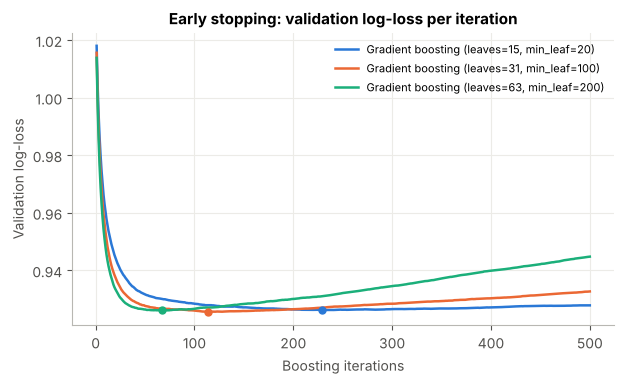

In [20]:
# --- Gradient boosting with early stopping on the validation set ----------------
# We train with a generous number of iterations, then read the validation log-loss after
# every iteration (staged predictions) and keep the best iteration count.
HGB_CONFIGS = [
    {"max_leaf_nodes": 15, "min_samples_leaf": 20},
    {"max_leaf_nodes": 31, "min_samples_leaf": 100},
    {"max_leaf_nodes": 63, "min_samples_leaf": 200},
]


def fit_hgb_with_validation(X_tr, y_tr, X_va, y_va, config, max_iter, categorical_idx):
    """Fit gradient boosting; return the model, the best iteration count, the validation
    probabilities at that iteration and the full validation log-loss curve."""
    model = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=max_iter, l2_regularization=1.0,
                                           early_stopping=False, categorical_features=categorical_idx,
                                           random_state=SEED, **config)
    model.fit(X_tr, y_tr)
    labels = np.unique(y_tr)
    losses, best_loss, best_proba = [], np.inf, None
    for proba in model.staged_predict_proba(X_va):
        loss = log_loss(y_va, np.clip(proba, 1e-15, 1.0), labels=labels)
        losses.append(loss)
        if loss < best_loss:
            best_loss, best_proba = loss, proba.copy()
    best_iter = int(np.argmin(losses)) + 1
    return model, best_iter, best_proba, np.array(losses)


def staged_proba_at(model, X, n_iter):
    """Probabilities of a boosting model after exactly `n_iter` iterations."""
    for i, proba in enumerate(model.staged_predict_proba(X), start=1):
        if i == n_iter:
            return proba
    raise ValueError("n_iter larger than the number of fitted iterations")


hgb_curves, hgb_best_iter = {}, {}
for config in HGB_CONFIGS:
    t0 = time.time()
    model, best_iter, best_val_proba, losses = fit_hgb_with_validation(
        X_train, y_train, X_val, y_val, config, SETTINGS["hgb_max_iter"], CAT_IDX)
    name = "Gradient boosting (leaves=%d, min_leaf=%d)" % (config["max_leaf_nodes"], config["min_samples_leaf"])
    fitted[name] = model
    hgb_curves[name] = losses
    hgb_best_iter[name] = best_iter
    row = evaluate(name, y_val, best_val_proba)
    row.update({"family": "gradient boosting", "fit_seconds": time.time() - t0,
                "setting": "max_leaf_nodes=%d, min_samples_leaf=%d, iterations=%d"
                           % (config["max_leaf_nodes"], config["min_samples_leaf"], best_iter)})
    validation_rows.append(row)
    print("%-48s best iteration %3d  val macro-F1 %.4f  (%.0fs)" % (name, best_iter, row["macro_f1"], row["fit_seconds"]))

fig = plotting.validation_curves(hgb_curves, "Early stopping: validation log-loss per iteration")
plotting.save_show(fig, "04_hgb_validation_curves")

In [21]:
# --- Selection -------------------------------------------------------------
validation_table = pd.DataFrame(validation_rows).set_index("model")
validation_table = validation_table[["family", "setting", "accuracy", "balanced_accuracy", "macro_f1", "log_loss", "fit_seconds"]]
save_table(validation_table.round(4), "validation_results")

candidates = validation_table[validation_table["family"] != "baseline"]
best_per_family = candidates.groupby("family")["macro_f1"].idxmax().to_dict()
FINAL_NAME = candidates["macro_f1"].idxmax()
FINAL_FAMILY = candidates.loc[FINAL_NAME, "family"]
print("Best setting per family (validation macro-F1):")
for family, name in best_per_family.items():
    print("  %-20s -> %s" % (family, name))
print("\nSelected final model:", FINAL_NAME)
RESULTS["validation"] = validation_table.reset_index().round(4).to_dict(orient="records")
RESULTS["selection"] = {"best_per_family": best_per_family, "final_model": FINAL_NAME}
validation_table.sort_values("macro_f1", ascending=False).round(4)

Best setting per family (validation macro-F1):
  gradient boosting    -> Gradient boosting (leaves=63, min_leaf=200)
  logistic regression  -> Logistic regression (C=1.0)
  random forest        -> Random forest (min_leaf=5)

Selected final model: Gradient boosting (leaves=63, min_leaf=200)


,family,setting,accuracy,balanced_accuracy,macro_f1,log_loss,fit_seconds
model,,,,,,,
"Gradient boosting (leaves=63, min_leaf=200)",gradient boosting,"max_leaf_nodes=63, min_samples_leaf=200, itera...",0.5424,0.4788,0.4875,0.9261,35.4442
"Gradient boosting (leaves=31, min_leaf=100)",gradient boosting,"max_leaf_nodes=31, min_samples_leaf=100, itera...",0.5425,0.4785,0.4872,0.9256,28.5219
"Gradient boosting (leaves=15, min_leaf=20)",gradient boosting,"max_leaf_nodes=15, min_samples_leaf=20, iterat...",0.5417,0.4772,0.4858,0.9262,29.3428
Random forest (min_leaf=5),random forest,min_samples_leaf=5,0.5330,0.4617,0.4685,0.9390,20.8815
Random forest (min_leaf=25),random forest,min_samples_leaf=25,0.5341,0.4530,0.4564,0.9378,16.5589
Logistic regression (C=1.0),logistic regression,C=1.0,0.5156,0.4266,0.4241,0.9637,2.9330
Logistic regression (C=0.1),logistic regression,C=0.1,0.5157,0.4264,0.4237,0.9637,3.0706
Lookup table,baseline,-,0.5074,0.4037,0.3875,0.9850,0.0000
Majority class,baseline,-,0.4825,0.3333,0.2170,1.0362,0.0000


**How to read this.** The table is sorted by validation macro-F1. Look first at the gap between the lookup table (38.8%) and the learned models: that gap is what machine learning adds. Gradient boosting leads (48.6%-48.8% for the three tree sizes), ahead of the random forest (46.9%) and logistic regression (42.4%). The three gradient boosting settings are within 0.2 points of each other, so the choice between them hardly matters; the rule picks the one with 63 leaves and 67 iterations. The early-stopping chart shows why the iteration count matters: validation log-loss first falls, then rises again once the model starts to memorise the training data; the dot marks the chosen iteration.

In [22]:
# --- Freeze the final models (one per family) ---------------------------------
# Gradient boosting: refit with exactly the chosen number of iterations, so the stored model
# is the early-stopped one. (Training is deterministic, so this equals the staged prediction.)
final_models = {}
for family, name in best_per_family.items():
    if family == "gradient boosting":
        config = HGB_CONFIGS[[("leaves=%d, min_leaf=%d" % (c["max_leaf_nodes"], c["min_samples_leaf"])) in name
                              for c in HGB_CONFIGS].index(True)]
        HGB_FINAL_CONFIG = dict(config)
        HGB_FINAL_ITER = hgb_best_iter[name]
        model = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=HGB_FINAL_ITER, l2_regularization=1.0,
                                               early_stopping=False, categorical_features=CAT_IDX,
                                               random_state=SEED, **HGB_FINAL_CONFIG)
        final_models[name] = model.fit(X_train, y_train)
    else:
        final_models[name] = fitted[name]

# Free memory used by the settings that were not selected
for name in list(fitted):
    if name not in final_models:
        del fitted[name]
RESULTS["selection"]["hgb_config"] = HGB_FINAL_CONFIG
RESULTS["selection"]["hgb_iterations"] = HGB_FINAL_ITER
print("Frozen models:", list(final_models))
print("Gradient boosting configuration used later in Sections 9.4 and 11:", HGB_FINAL_CONFIG, "iterations:", HGB_FINAL_ITER)

Frozen models: ['Gradient boosting (leaves=63, min_leaf=200)', 'Logistic regression (C=1.0)', 'Random forest (min_leaf=5)']
Gradient boosting configuration used later in Sections 9.4 and 11: {'max_leaf_nodes': 63, 'min_samples_leaf': 200} iterations: 67


## 9. Final test evaluation

From here on, the design is frozen: the models above, the decision rule (predict the most likely class), and the metrics. The test patients are used for the first time.

We report, for every model on the **same test set**: accuracy, balanced accuracy (mean recall over classes), macro-F1 and log-loss (lower is better; it rewards confident correct probabilities and punishes confident mistakes). To show how much the scores would vary with a different sample of patients, we add **95% bootstrap intervals** that resample *patients* (not rows), matching the grouped design.

In [23]:
def model_inputs(name):
    """Logistic regression takes the raw columns (its pipeline encodes them); trees take X arrays."""
    return "frame" if name.startswith("Logistic") else "array"


test_proba = {
    "Majority class": majority.predict_proba(X_test),
    "Lookup table": lookup_table_probabilities(train_df, test_df, LOOKUP_KEYS),
}
for name, model in final_models.items():
    test_proba[name] = model.predict_proba(test_df[FEATURES] if model_inputs(name) == "frame" else X_test)

test_table = pd.DataFrame([evaluate(n, y_test, p) for n, p in test_proba.items()]).set_index("model")

# Patient-level bootstrap: resample test patients with replacement, weight their admissions
test_patient_ids = test_df["patientid"].to_numpy()
unique_patients, patient_pos = np.unique(test_patient_ids, return_inverse=True)
rng_boot = np.random.default_rng(SEED)
test_pred = {n: p.argmax(axis=1) for n, p in test_proba.items()}
boot = {n: {"accuracy": [], "macro_f1": []} for n in test_proba}
for _ in range(SETTINGS["bootstrap_reps"]):
    draw = rng_boot.integers(0, len(unique_patients), len(unique_patients))
    weights = np.bincount(draw, minlength=len(unique_patients))[patient_pos]
    for n, pred in test_pred.items():
        boot[n]["accuracy"].append(np.average(pred == y_test, weights=weights))
        boot[n]["macro_f1"].append(f1_score(y_test, pred, average="macro", sample_weight=weights))
for n in test_proba:
    for metric in ["accuracy", "macro_f1"]:
        low, high = np.percentile(boot[n][metric], [2.5, 97.5])
        test_table.loc[n, metric + "_ci_low"] = low
        test_table.loc[n, metric + "_ci_high"] = high

test_table = test_table[["accuracy", "accuracy_ci_low", "accuracy_ci_high", "macro_f1", "macro_f1_ci_low",
                         "macro_f1_ci_high", "balanced_accuracy", "log_loss"]]
save_table(test_table.round(4), "test_results")
RESULTS["test"] = test_table.reset_index().round(4).to_dict(orient="records")
test_table.round(4)

,accuracy,accuracy_ci_low,accuracy_ci_high,macro_f1,macro_f1_ci_low,macro_f1_ci_high,balanced_accuracy,log_loss
model,,,,,,,,
Majority class,0.4869,0.4823,0.4915,0.2183,0.2169,0.2197,0.3333,1.0326
Lookup table,0.5062,0.5014,0.5108,0.3840,0.3790,0.3881,0.4000,0.9840
"Gradient boosting (leaves=63, min_leaf=200)",0.5409,0.5367,0.5450,0.4847,0.4802,0.4894,0.4760,0.9270
Logistic regression (C=1.0),0.5157,0.5109,0.5196,0.4212,0.4165,0.4251,0.4236,0.9635
Random forest (min_leaf=5),0.5354,0.5318,0.5393,0.4699,0.4653,0.4743,0.4626,0.9387


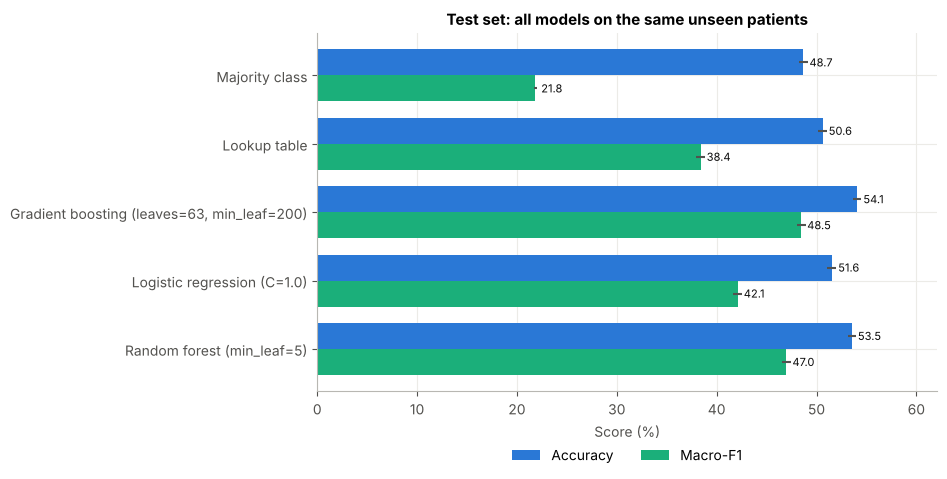

Final model minus runner-up (Random forest (min_leaf=5)):
  macro-F1 difference: +0.0148  (95% CI +0.0113 to +0.0184)
  accuracy difference: +0.0055  (95% CI +0.0022 to +0.0086)
Final model minus lookup table, macro-F1: +0.1008  (95% CI +0.0954 to +0.1059)


In [24]:
order = list(test_table.index)
fig = plotting.model_scores(
    order, test_table["accuracy"].values, test_table["macro_f1"].values,
    "Test set: all models on the same unseen patients",
    err_acc=np.vstack([test_table["accuracy"] - test_table["accuracy_ci_low"], test_table["accuracy_ci_high"] - test_table["accuracy"]]),
    err_f1=np.vstack([test_table["macro_f1"] - test_table["macro_f1_ci_low"], test_table["macro_f1_ci_high"] - test_table["macro_f1"]]))
plotting.save_show(fig, "05_test_model_comparison")

# Is the final model's lead over the runner-up larger than sampling noise?
others = [n for n in final_models if n != FINAL_NAME]
runner_up = max(others, key=lambda n: test_table.loc[n, "macro_f1"])
diff = np.array(boot[FINAL_NAME]["macro_f1"]) - np.array(boot[runner_up]["macro_f1"])
diff_acc = np.array(boot[FINAL_NAME]["accuracy"]) - np.array(boot[runner_up]["accuracy"])
diff_lookup = np.array(boot[FINAL_NAME]["macro_f1"]) - np.array(boot["Lookup table"]["macro_f1"])
RESULTS["test_differences"] = {
    "runner_up": runner_up,
    "macro_f1_diff_vs_runner_up": [float(np.mean(diff)), float(np.percentile(diff, 2.5)), float(np.percentile(diff, 97.5))],
    "accuracy_diff_vs_runner_up": [float(np.mean(diff_acc)), float(np.percentile(diff_acc, 2.5)), float(np.percentile(diff_acc, 97.5))],
    "macro_f1_diff_vs_lookup": [float(np.mean(diff_lookup)), float(np.percentile(diff_lookup, 2.5)), float(np.percentile(diff_lookup, 97.5))],
}
print("Final model minus runner-up (%s):" % runner_up)
print("  macro-F1 difference: %+.4f  (95%% CI %+.4f to %+.4f)" % tuple(RESULTS["test_differences"]["macro_f1_diff_vs_runner_up"]))
print("  accuracy difference: %+.4f  (95%% CI %+.4f to %+.4f)" % tuple(RESULTS["test_differences"]["accuracy_diff_vs_runner_up"]))
print("Final model minus lookup table, macro-F1: %+.4f  (95%% CI %+.4f to %+.4f)" % tuple(RESULTS["test_differences"]["macro_f1_diff_vs_lookup"]))

**How to read this.** Error bars are 95% patient-bootstrap intervals. The final model reaches **54.1% accuracy** (CI 53.7-54.5) and **48.5% macro-F1** (CI 48.0-48.9), compared with 50.6% / 38.4% for the lookup table and 48.7% / 21.8% for the majority rule. The paired differences printed below the chart compare models on the same resampled patients: the lead over the random forest is small but larger than the sampling noise (+1.5 macro-F1 points, CI +1.1 to +1.8). The validation and test scores are close, which suggests that the selection did not overfit the validation set.

### 9.2 Per-class results and confusion matrix of the final model

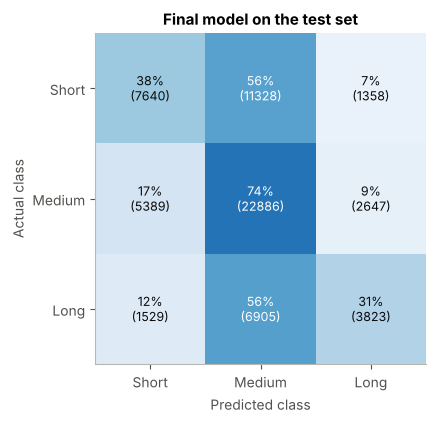

,precision,recall,f1,support
Short,0.525,0.376,0.438,20326
Medium,0.557,0.740,0.635,30922
Long,0.488,0.312,0.381,12257


In [25]:
final_test_proba = test_proba[FINAL_NAME]
final_pred = final_test_proba.argmax(axis=1)
precision, recall, f1, support = precision_recall_fscore_support(y_test, final_pred, labels=[0, 1, 2])
per_class = pd.DataFrame({"precision": precision, "recall": recall, "f1": f1, "support": support}, index=CLASS_NAMES)
save_table(per_class.round(4), "final_per_class")
RESULTS["final_per_class"] = per_class.round(4).reset_index().rename(columns={"index": "class"}).to_dict(orient="records")

cm = confusion_matrix(y_test, final_pred, labels=[0, 1, 2])
RESULTS["final_confusion_matrix"] = cm.tolist()
fig = plotting.confusion(cm, "Final model on the test set")
plotting.save_show(fig, "06_confusion_matrix")
per_class.round(3)

**How to read this.** Rows are the true class, columns the prediction; percentages are shares of each true class, so the diagonal is per-class recall. The model leans towards the largest class: Medium recall is 74%, while Short (38%) and Long (31%) are often predicted as Medium. Errors are mostly between *neighbouring* classes: Short and Long are confused with each other (7% of Short stays predicted Long, 12% of Long stays predicted Short) much less often than either is confused with Medium.

### 9.3 Ranking admissions by risk of a long stay

For screening (Section 11.5) we need the predicted probability of a Long stay, P(Long), to *rank* admissions well. We measure this with ROC-AUC (probability that a random Long stay is ranked above a random non-Long stay; 0.5 = random) and average precision (area under the precision-recall curve; the random value equals the Long share, about 0.20).

In [26]:
ranking_rows = []
for name, proba in test_proba.items():
    if name == "Majority class":
        continue  # constant probabilities cannot rank
    ranking_rows.append({"model": name, "roc_auc_long": roc_auc_score(test_df["is_long"], proba[:, 2]),
                         "average_precision_long": average_precision_score(test_df["is_long"], proba[:, 2])})
ranking_table = pd.DataFrame(ranking_rows).set_index("model")
ranking_table.loc["Random ranking (reference)"] = [0.5, test_df["is_long"].mean()]
save_table(ranking_table.round(4), "test_long_stay_ranking")
RESULTS["long_stay_ranking"] = ranking_table.reset_index().round(4).to_dict(orient="records")
ranking_table.round(4)

,roc_auc_long,average_precision_long
model,,
Lookup table,0.6830,0.3369
"Gradient boosting (leaves=63, min_leaf=200)",0.7518,0.4323
Logistic regression (C=1.0),0.7084,0.3617
Random forest (min_leaf=5),0.7416,0.4200
Random ranking (reference),0.5000,0.1930


**How to read this.** Although the final model predicts "Long" for only 31% of the actual Long stays, its probabilities *rank* admissions well: ROC-AUC 0.752 and average precision 0.432 (random: 0.193), better than the lookup table (0.683 / 0.337). Ranking, not the most-likely-class label, is what the screening use in Section 11.5 needs.

### 9.4 Supplementary experiments: Visitors and retrospective patient aggregates

These experiments were run **after the main design was frozen** and were **not used to choose anything**. They answer two questions: how much would `Visitors with Patient` add if it were available at admission, and how much do the cross-admission patient aggregates (which use other, possibly future, admissions of the same patient) add?

All variants use the selected gradient boosting configuration; only the feature set changes, and the iteration count is chosen on the validation set as before. The patient aggregates are computed within each patient only. Because the split is by patient, they never use information from another set, but they **do** use the patient's other admissions regardless of timing, so they describe a *retrospective* analysis and are **not deployable** at admission.

In [27]:
# Retrospective, label-free patient aggregates (computed within each patient; uses ALL of that patient's admissions)
by_patient = df.groupby("patientid")
df["pt_n_admissions"] = by_patient["case_id"].transform("size")
df["pt_n_hospitals"] = by_patient["Hospital_code"].transform("nunique")
df["pt_mean_severity"] = by_patient["Severity of Illness"].transform("mean")
df["pt_mean_deposit"] = by_patient["Admission_Deposit"].transform("mean")
df["pt_deposit_ratio"] = df["Admission_Deposit"] / df["pt_mean_deposit"]
df["pt_same_hospital"] = df.groupby(["patientid", "Hospital_code"])["case_id"].transform("size")
df["pt_mean_visitors"] = by_patient["Visitors with Patient"].transform("mean")        # visitor-derived
df["pt_visitors_diff"] = df["Visitors with Patient"] - df["pt_mean_visitors"]        # visitor-derived

PATIENT_AGG = ["pt_n_admissions", "pt_n_hospitals", "pt_mean_severity", "pt_mean_deposit",
               "pt_deposit_ratio", "pt_same_hospital"]
VISITOR_AGG = ["pt_mean_visitors", "pt_visitors_diff"]
supplementary_sets = {
    "Main (admission-time features)": MAIN_NUMERIC,
    "Main + Visitors": MAIN_NUMERIC + ["Visitors with Patient"],
    "Main + patient aggregates (retrospective)": MAIN_NUMERIC + PATIENT_AGG,
    "Main + Visitors + all aggregates (retrospective)": MAIN_NUMERIC + ["Visitors with Patient"] + PATIENT_AGG + VISITOR_AGG,
}

sup_train, sup_val, sup_test = df.iloc[train_idx], df.iloc[val_idx], df.iloc[test_idx]
supplementary_rows = []
for label, numeric in supplementary_sets.items():
    prep = make_tree_preprocessor(MAIN_CATEGORICAL, numeric).fit(sup_train[MAIN_CATEGORICAL + numeric])
    Xs_tr, Xs_va, Xs_te = (prep.transform(d[MAIN_CATEGORICAL + numeric]) for d in (sup_train, sup_val, sup_test))
    model, best_iter, _, _ = fit_hgb_with_validation(Xs_tr, y_train, Xs_va, y_val, HGB_FINAL_CONFIG,
                                                     SETTINGS["hgb_max_iter"], CAT_IDX)
    proba = staged_proba_at(model, Xs_te, best_iter)
    row = evaluate(label, y_test, proba)
    row["roc_auc_long"] = roc_auc_score(test_df["is_long"], proba[:, 2])
    row["iterations"] = best_iter
    row["deployable at admission?"] = "yes" if label.startswith("Main (") else (
        "only if visitors are known at admission" if label == "Main + Visitors" else "no (uses other admissions)")
    supplementary_rows.append(row)
    print("%-52s test accuracy %.4f  macro-F1 %.4f" % (label, row["accuracy"], row["macro_f1"]))

supplementary_table = pd.DataFrame(supplementary_rows).set_index("model")
save_table(supplementary_table.round(4), "supplementary_feature_sets")
RESULTS["supplementary"] = supplementary_table.reset_index().round(4).to_dict(orient="records")
supplementary_table.round(4)

Main (admission-time features)                       test accuracy 0.5409  macro-F1 0.4847
Main + Visitors                                      test accuracy 0.6268  macro-F1 0.6232
Main + patient aggregates (retrospective)            test accuracy 0.5506  macro-F1 0.5007
Main + Visitors + all aggregates (retrospective)     test accuracy 0.6292  macro-F1 0.6250


,accuracy,balanced_accuracy,macro_f1,log_loss,roc_auc_long,iterations,deployable at admission?
model,,,,,,,
Main (admission-time features),0.5409,0.4760,0.4847,0.9270,0.7518,67,yes
Main + Visitors,0.6268,0.6172,0.6232,0.7761,0.8931,98,only if visitors are known at admission
Main + patient aggregates (retrospective),0.5506,0.4906,0.5007,0.9131,0.7702,64,no (uses other admissions)
Main + Visitors + all aggregates (retrospective),0.6292,0.6199,0.6250,0.7695,0.8977,91,no (uses other admissions)


**How to read this.** The first row reproduces the main model exactly (same configuration, same validation rule). Adding `Visitors with Patient` raises accuracy from 54.1% to **62.7%** and macro-F1 from 48.5% to 62.3%: by far the largest single gain in this study, and the reason why its recording time matters so much. The retrospective patient aggregates add only 1.0 accuracy points; that gain would in any case not be available to a hospital at the moment of admission.

### 9.5 Controlled comparison with the original approach

The original project reported about 61% accuracy, but under different conditions: a random split of *admissions* (the same patient could be in training and test), `Visitors with Patient` as a feature, hospital codes removed, and XGBoost hyper-parameters tuned on the test set. Its number is therefore **not directly comparable** with Section 9.1.

To separate the effect of each change, we re-create the original random forest (its feature encoding and its tuned hyper-parameters, taken from the original notebook) and evaluate it under different conditions. The original XGBoost was not re-run (`xgboost` was not available in the environment used for this run, and this project keeps its requirements to scikit-learn), so the random forest stands in for the original approach; the original reported similar accuracy for both models.

In [28]:
ORIGINAL_RF_PARAMS = {"n_estimators": 271 if not QUICK else 60, "max_depth": 13, "min_samples_split": 2,
                      "min_samples_leaf": 7, "max_features": "log2", "criterion": "entropy",
                      "bootstrap": False, "random_state": 0, "n_jobs": -1}


def original_style_features(frame, include_visitors):
    """Feature matrix as built in the original notebook: ordinal codes for admission type,
    severity and age, mode-filled Bed Grade, one-hot (drop first) for four nominal columns,
    and no hospital, city or patient codes."""
    out = pd.DataFrame(index=frame.index)
    out["Available Extra Rooms in Hospital"] = frame["Available Extra Rooms in Hospital"]
    out["Bed Grade"] = frame["Bed Grade"].fillna(df["Bed Grade"].mode()[0])   # original: mode of the full data
    out["Type of Admission"] = frame["Type of Admission"].map({"Urgent": 0, "Trauma": 1, "Emergency": 2})
    out["Severity of Illness"] = frame["Severity of Illness"]
    out["Age"] = frame["Age"]
    out["Admission_Deposit"] = frame["Admission_Deposit"]
    if include_visitors:
        out["Visitors with Patient"] = frame["Visitors with Patient"]
    dummies = pd.get_dummies(frame[["Hospital_type_code", "Department", "Ward_Type", "Ward_Facility_Code"]],
                             drop_first=True, dtype=float)
    return pd.concat([out, dummies], axis=1)


controlled_rows = []
# C1: original conditions - random admission-level 75/25 split, as in the original notebook
X_orig = original_style_features(df, include_visitors=True)
Xo_tr, Xo_te, yo_tr, yo_te = train_test_split(X_orig, df["los_class"], test_size=0.25, random_state=0)
rf_orig = RandomForestClassifier(**ORIGINAL_RF_PARAMS).fit(Xo_tr, yo_tr)
row = evaluate("C1 original RF, original features, random admission split", yo_te.to_numpy(), rf_orig.predict_proba(Xo_te))
row.update({"split": "random admissions 75/25", "test set": "own random 25%", "visitors": "yes"})
controlled_rows.append(row)

# C2/C3: same model and encoding, but trained on our training patients and scored on our test patients
for include_visitors in [True, False]:
    Xo = original_style_features(df, include_visitors=include_visitors)
    rf_orig = RandomForestClassifier(**ORIGINAL_RF_PARAMS).fit(Xo.iloc[train_idx], y_train)
    tag = "C2 original RF, original features" if include_visitors else "C3 original RF, original features without Visitors"
    row = evaluate(tag + ", patient split", y_test, rf_orig.predict_proba(Xo.iloc[test_idx]))
    row.update({"split": "by patient (this study)", "test set": "this study's test set",
                "visitors": "yes" if include_visitors else "no"})
    controlled_rows.append(row)
del rf_orig

# New pipeline rows (same test set), taken from Section 9.4
for label, tag in [("Main + Visitors", "N1 new pipeline + Visitors, patient split"),
                   ("Main (admission-time features)", "N2 new pipeline, main features, patient split")]:
    r = supplementary_table.loc[label]
    controlled_rows.append({"model": tag, "accuracy": r["accuracy"], "balanced_accuracy": r["balanced_accuracy"],
                            "macro_f1": r["macro_f1"], "log_loss": r["log_loss"], "split": "by patient (this study)",
                            "test set": "this study's test set", "visitors": "yes" if "Visitors" in label else "no"})

controlled_table = pd.DataFrame(controlled_rows).set_index("model")[
    ["split", "test set", "visitors", "accuracy", "macro_f1", "balanced_accuracy", "log_loss"]]
save_table(controlled_table.round(4), "controlled_comparison")
RESULTS["controlled"] = controlled_table.reset_index().round(4).to_dict(orient="records")
controlled_table.round(4)

,split,test set,visitors,accuracy,macro_f1,balanced_accuracy,log_loss
model,,,,,,,
"C1 original RF, original features, random admission split",random admissions 75/25,own random 25%,yes,0.6051,0.5905,0.5944,0.8070
"C2 original RF, original features, patient split",by patient (this study),this study's test set,yes,0.6023,0.5849,0.5904,0.8095
"C3 original RF, original features without Visitors, patient split",by patient (this study),this study's test set,no,0.5238,0.4247,0.4311,0.9473
"N1 new pipeline + Visitors, patient split",by patient (this study),this study's test set,yes,0.6268,0.6232,0.6172,0.7761
"N2 new pipeline, main features, patient split",by patient (this study),this study's test set,no,0.5409,0.4847,0.4760,0.9270


**How to read this.**
* **C1 vs the original 61%**: C1 re-creates the original setting and reaches 60.5%, so the original result is reproduced in substance (exact equality is not expected: software versions differ and the original XGBoost tuning is not re-created).
* **C1 vs C2**: same model and features, different split: -0.3 points. C2 also trains on fewer admissions (60% of patients instead of 75% of admissions), so this small difference mixes the split effect with a training-size effect. The patient split matters little here, probably because the original features contain little that identifies a patient.
* **C2 vs C3**: removing `Visitors with Patient` changes accuracy by -7.8 points. This explains most of the gap between 61% and the main result of this study.
* **C2 vs N1** (both with Visitors, same test set): the new pipeline adds +2.5 accuracy points (+3.8 macro-F1). **C3 vs N2** (both without Visitors): +1.7 points (+6.0 macro-F1). This is the measurable improvement from the method itself: hospital codes kept, native categorical handling, gradient boosting with early stopping.
* **N2** is the main result of this study. It answers a stricter question than the original, so its lower number does not mean a worse method.

## 10. Interpretation and error analysis

### 10.1 Which features does the final model rely on?

**Permutation importance:** shuffle one feature at a time in the test data and measure how much macro-F1 drops. A large drop means the model relies on that feature. It describes the *model*, not causation, and correlated features (e.g. hospital code and hospital type) share credit: shuffling one leaves the other available, so both can look less important than the information they carry together.

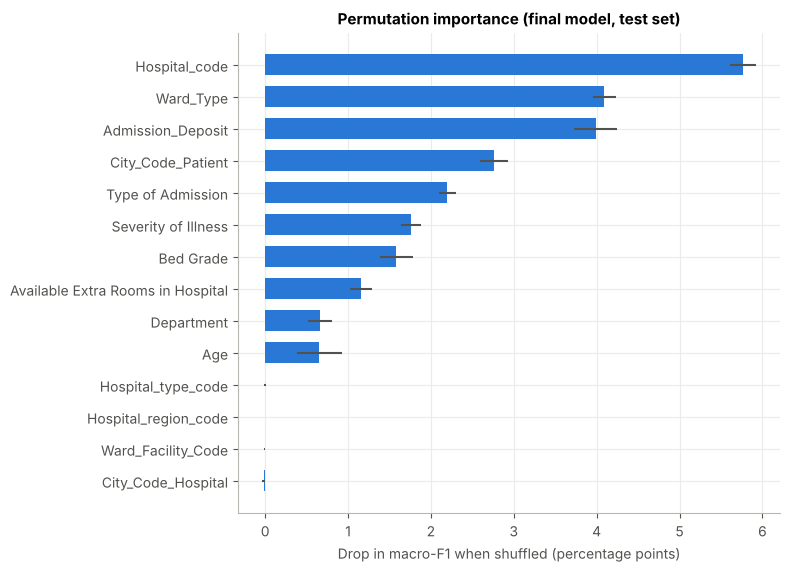

,macro_f1_drop,std
Hospital_code,0.0576,0.0016
Ward_Type,0.0409,0.0014
Admission_Deposit,0.0399,0.0026
City_Code_Patient,0.0276,0.0017
Type of Admission,0.0220,0.0010
Severity of Illness,0.0176,0.0012
Bed Grade,0.0158,0.0020
Available Extra Rooms in Hospital,0.0115,0.0013
Department,0.0066,0.0015
Age,0.0065,0.0027


In [29]:
rng_imp = np.random.default_rng(SEED)
imp_rows = rng_imp.choice(len(test_df), size=min(SETTINGS["importance_rows"], len(test_df)), replace=False)
final_model = final_models[FINAL_NAME]
X_imp = test_df[FEATURES].iloc[imp_rows] if model_inputs(FINAL_NAME) == "frame" else X_test[imp_rows]
importance = permutation_importance(final_model, X_imp, y_test[imp_rows], scoring="f1_macro",
                                    n_repeats=SETTINGS["importance_repeats"], random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({"macro_f1_drop": importance.importances_mean, "std": importance.importances_std},
                                index=FEATURES).sort_values("macro_f1_drop", ascending=False)
save_table(importance_table.round(4), "permutation_importance")
RESULTS["permutation_importance"] = importance_table["macro_f1_drop"].round(4).to_dict()
fig = plotting.horizontal_bars(list(importance_table.index), importance_table["macro_f1_drop"].values * 100,
                               "Permutation importance (final model, test set)",
                               "Drop in macro-F1 when shuffled (percentage points)",
                               errors=importance_table["std"].values * 100)
plotting.save_show(fig, "07_permutation_importance")
importance_table.round(4)

**How to read this.** The model relies most on Hospital code (5.8 pp), Ward Type (4.1 pp), Admission Deposit (4.0 pp), City Code Patient (2.8 pp), Type of Admission (2.2 pp). The four hospital-level columns (Hospital type code, Hospital region code, Ward Facility Code, City Code Hospital) show no importance: they are fixed per hospital, so once `Hospital_code` is known they carry no extra information. The deposit matters more than Section 4.3 suggested, because its meaning depends on the hospital and ward (the model uses it in combination with them).

### 10.2 The interpretable model: what pushes a prediction towards Long?

The logistic regression is less accurate but easy to read. Its coefficients for the Long class (relative to the other classes, on standardised numbers and one-hot categories) show which characteristics raise the predicted odds of a long stay.

In [30]:
lr_name = best_per_family["logistic regression"]
lr_model = final_models[lr_name]
lr_names = lr_model.named_steps["prep"].get_feature_names_out()
long_coef = pd.Series(lr_model.named_steps["model"].coef_[2], index=lr_names)
coef_view = pd.concat([long_coef.sort_values(ascending=False).head(8), long_coef.sort_values().head(5)])
coef_view.index = [i.replace("cat__", "").replace("num__", "") for i in coef_view.index]
RESULTS["lr_long_coefficients_top"] = coef_view.round(3).to_dict()
coef_view.round(3).to_frame("coefficient for Long (log-odds)")

,coefficient for Long (log-odds)
Ward_Type_S,0.533
City_Code_Patient_3,0.523
Hospital_code_29,0.393
Department_surgery,0.324
Hospital_code_5,0.208
Severity of Illness,0.197
City_Code_Patient_15,0.193
Hospital_code_16,0.192
Ward_Type_P,-0.612
Ward_Type_Q,-0.420


**How to read this.** Positive values raise the predicted odds of a Long stay, negative values lower them, all else equal in the model. For one-hot categories the comparison is against the average category, so the values are relative, not absolute effects.

### 10.3 Where does the final model make mistakes?

In [31]:
analysis = test_df[["Severity of Illness", "Ward_Type", "Type of Admission", "Age", "Department", "los_class", "is_long"]].copy()
analysis["pred"] = final_pred
analysis["correct"] = (analysis["pred"] == analysis["los_class"]).astype(int)
analysis["flag_long"] = (analysis["pred"] == 2).astype(int)
analysis["age_group"] = pd.cut(analysis["Age"], bins=[-1, 2, 5, 9], labels=["0-30", "31-60", "61-100"]).astype(str)
analysis["severity"] = analysis["Severity of Illness"].map({0: "Minor", 1: "Moderate", 2: "Extreme"})

group_rows = []
for col in ["severity", "Ward_Type", "Type of Admission", "age_group", "Department"]:
    for level, part in analysis.groupby(col):
        if len(part) < 300:
            continue
        long_part = part[part["is_long"] == 1]
        group_rows.append({"feature": col, "level": level, "admissions": len(part),
                           "% Long (actual)": part["is_long"].mean() * 100,
                           "accuracy %": part["correct"].mean() * 100,
                           "Long recall %": long_part["flag_long"].mean() * 100 if len(long_part) else np.nan})
error_by_group = pd.DataFrame(group_rows).set_index(["feature", "level"]).round(1)
save_table(error_by_group, "error_by_group")
error_by_group

admissions  % Long (actual)  accuracy %  Long recall %
feature           level                                                                     
severity          Extreme                  11547             26.4        54.8           43.8
                  Minor                    17332             13.7        52.3           13.1
                  Moderate                 34626             19.8        54.7           31.8
Ward_Type         P                         1034              6.6        60.7            0.0
                  Q                        20991             10.8        58.3            9.3
                  R                        25599             18.7        54.3           21.7
                  S                        15590             32.5        47.7           50.6
Type of Admission Emergency                23446             17.8        50.9           27.0
                  Trauma                   30279             21.5        56.7           36.1
                  Urgent                    9780             16.1        53.8           22.0
age_group         0-30                     12802             15.3        53.1           18.8
                  31-60                    35152             19.2        55.0           32.9
                  61-100                   15551             22.7        52.9           34.7
Department        TB & Chest disease        1938             19.5        48.6           11.9
                  anesthesia                5847             15.7        54.1           15.2
                  gynecology               49770             19.5        54.6           32.7
                  radiotherapy              5694             20.6        51.5           35.2

In [32]:
# What happens to the actual Long stays?
long_rows = analysis[analysis["is_long"] == 1]
where_long_go = long_rows["pred"].value_counts(normalize=True).reindex([0, 1, 2]).fillna(0)
where_long_go.index = ["predicted Short", "predicted Medium", "predicted Long"]
print("Actual Long stays in the test set:", len(long_rows))
print((where_long_go * 100).round(1).to_string())

# Compare caught vs missed Long stays on a few characteristics
caught = long_rows[long_rows["pred"] == 2]
missed = long_rows[long_rows["pred"] != 2]
compare = pd.DataFrame({
    "caught Long stays": [len(caught), (caught["severity"] == "Extreme").mean() * 100,
                          caught["Ward_Type"].isin(["S", "T"]).mean() * 100, caught["Age"].mean()],
    "missed Long stays": [len(missed), (missed["severity"] == "Extreme").mean() * 100,
                          missed["Ward_Type"].isin(["S", "T"]).mean() * 100, missed["Age"].mean()],
}, index=["count", "% Extreme severity", "% in ward S or T", "mean age band (0-9)"]).round(1)
RESULTS["long_stays_predicted_as"] = (where_long_go.round(4)).to_dict()
compare

Actual Long stays in the test set: 12257
predicted Short     12.5
predicted Medium    56.3
predicted Long      31.2


,caught Long stays,missed Long stays
count,3823.0,8434.0
% Extreme severity,34.9,20.3
% in ward S or T,67.2,30.3
mean age band (0-9),4.7,4.3


**How to read this.** The subgroup table shows where accuracy and the recall of Long stays are lower. Long recall is much higher for Extreme severity and for ward S than for minor cases or wards P and Q. Of the actual Long stays, 31% are predicted Long, 56% Medium and only 12% Short. The comparison of caught and missed Long stays shows that the model mainly catches Long stays that "look" long at admission (more often Extreme severity, mostly wards S and T); Long stays that look like ordinary admissions are hard to anticipate from these fields.

### 10.4 Can the predicted probabilities be taken at face value?

Early stopping on log-loss tends to give sensible probabilities, but it does not prove it. We check P(Long) directly on the test set with a **reliability diagram**: admissions are sorted into 10 groups by predicted P(Long); for each group we compare the mean prediction with the observed share of Long stays. We also report the **Brier score** (mean squared error of the probability; lower is better) against a constant prediction equal to the training Long share, and the **expected calibration error** (ECE, the average gap between prediction and observation, weighted by group size).

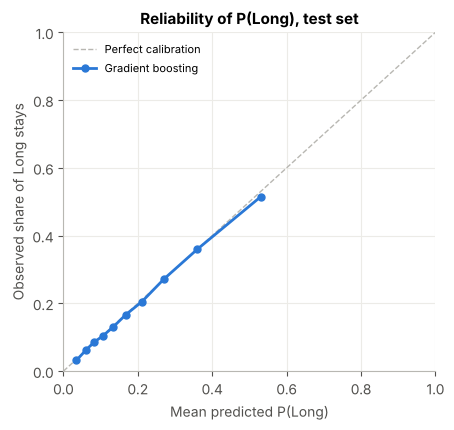

ECE 0.0038 | Brier model 0.1341 vs constant 0.1558 | mean predicted 0.1954 vs observed 0.1930


,mean_pred,observed,n
bin,,,
0,0.035,0.032,6351
1,0.060,0.061,6350
2,0.081,0.085,6351
3,0.105,0.103,6350
4,0.133,0.130,6351
5,0.167,0.166,6350
6,0.211,0.205,6350
7,0.271,0.272,6351
8,0.360,0.360,6352


In [33]:
def reliability_table(y_binary, p, n_bins=10):
    """Group by quantiles of the predicted probability; compare mean prediction and observed rate."""
    frame = pd.DataFrame({"y": y_binary, "p": p})
    frame["bin"] = pd.qcut(frame["p"], q=n_bins, labels=False, duplicates="drop")
    table = frame.groupby("bin").agg(mean_pred=("p", "mean"), observed=("y", "mean"), n=("y", "size"))
    ece = float(np.sum(np.abs(table["mean_pred"] - table["observed"]) * table["n"]) / table["n"].sum())
    return table, ece


p_long_final = final_test_proba[:, 2]
rel, ece = reliability_table(test_df["is_long"].to_numpy(), p_long_final)
save_table(rel.round(4), "reliability_p_long")
brier_model = brier_score_loss(test_df["is_long"], p_long_final)
brier_constant = brier_score_loss(test_df["is_long"], np.full(len(test_df), train_df["is_long"].mean()))
RESULTS["calibration_p_long"] = {"ece": round(ece, 4), "brier_model": round(float(brier_model), 4),
                                 "brier_constant": round(float(brier_constant), 4),
                                 "mean_predicted": round(float(p_long_final.mean()), 4),
                                 "observed_rate": round(float(test_df["is_long"].mean()), 4),
                                 "max_bin_gap": round(float((rel["mean_pred"] - rel["observed"]).abs().max()), 4)}
fig = plotting.reliability(rel["mean_pred"].values, rel["observed"].values, rel["n"].values,
                           "Reliability of P(Long), test set", label=FINAL_NAME.split(" (")[0])
plotting.save_show(fig, "08_reliability_p_long")
print("ECE %.4f | Brier model %.4f vs constant %.4f | mean predicted %.4f vs observed %.4f"
      % (ece, brier_model, brier_constant, p_long_final.mean(), test_df["is_long"].mean()))
rel.round(3)

**How to read this.** Points on the diagonal mean that "a predicted 40% risk" really corresponds to about 40% Long stays. Here every decile lies close to the diagonal (ECE 0.004, largest gap 1.6%), and the Brier score (0.134) is clearly better than a constant prediction (0.156). So, on this test set, P(Long) can be read as a probability. Note also that even the riskiest tenth of admissions has a mean predicted risk of only 0.53: the model is rarely *sure* that a stay will be long, which is why the most-likely-class rule predicts Long less often (12% of test admissions) than Long stays occur (19%). This check covers P(Long) on this test set only; it says nothing about other hospitals or later years.

## 11. Operational use: simulated scenarios

The data have **no admission or discharge dates**. We therefore cannot simulate daily bed occupancy, staffing or real schedules. What we *can* study are two planning questions in simulated settings:

1. **Cumulative bed-day demand of a group of admissions.** If 100 patients are admitted to a hospital, how many bed-days will they need in total over their stays? This is the sum of their LOS. It is *not* the number of beds occupied on a given day, which would depend on when patients arrive and leave.
2. **Screening for likely long stays.** If a team can review only a fixed share of new admissions, how many of the eventual Long stays would be among them?

### 11.1 A model of the full LOS distribution

For bed-days we need a number of days per admission, so we fit a gradient boosting model on the **11 Stay bins** (same features, same training/validation rule, same configuration as the final 3-class model). It returns a probability for each bin; the **expected proxy days** of an admission is the sum over bins of probability times bin midpoint. This 11-bin model is used only in this section; the classification results above come from the directly trained 3-class models.

In [34]:
y_train_bin = train_df["stay_bin"].to_numpy()
y_val_bin = val_df["stay_bin"].to_numpy()
y_test_bin = test_df["stay_bin"].to_numpy()
t0 = time.time()
bin_model, bin_iter, val_bin_proba, bin_curve = fit_hgb_with_validation(
    X_train, y_train_bin, X_val, y_val_bin, HGB_FINAL_CONFIG, SETTINGS["hgb_max_iter_11bin"], CAT_IDX)
test_bin_proba = staged_proba_at(bin_model, X_test, bin_iter)
print("11-bin model: best iteration %d (%.0fs)" % (bin_iter, time.time() - t0))

bin_pred = test_bin_proba.argmax(axis=1)
bin_metrics = {
    "iterations": bin_iter,
    "test_accuracy_11bin": accuracy_score(y_test_bin, bin_pred),
    "test_within_one_bin": float(np.mean(np.abs(bin_pred - y_test_bin) <= 1)),
    "test_log_loss_11bin": log_loss(y_test_bin, np.clip(test_bin_proba, 1e-15, 1), labels=list(range(11))),
    "majority_bin_accuracy": float(np.mean(y_test_bin == np.bincount(y_train_bin).argmax())),
}
RESULTS["bin_model"] = {k: round(float(v), 4) for k, v in bin_metrics.items()}
pd.Series(bin_metrics).round(4).to_frame("11-bin model")

11-bin model: best iteration 40 (89s)


,11-bin model
iterations,40.0000
test_accuracy_11bin,0.3478
test_within_one_bin,0.6546
test_log_loss_11bin,1.7473
majority_bin_accuracy,0.2739


In [35]:
# Expected proxy days per admission, compared with simple averages learned on the training set
def lookup_mean_days(train_frame, target_frame, keys, days_col="proxy_days", min_count=30):
    """Mean proxy days per group of `keys` from training rows; fallback = overall training mean."""
    stats = train_frame.groupby(keys)[days_col].agg(["mean", "size"])
    stats = stats[stats["size"] >= min_count]["mean"]
    est = target_frame[keys].merge(stats.rename("est"), left_on=keys, right_index=True, how="left")["est"].to_numpy()
    return np.where(np.isnan(est), train_frame[days_col].mean(), est)


expected_days = {
    "Overall average": np.full(len(test_df), train_df["proxy_days"].mean()),
    "Hospital average": lookup_mean_days(train_df, test_df, ["Hospital_code"]),
    "Hospital x ward x severity average": lookup_mean_days(train_df, test_df, LOOKUP_KEYS),
    "11-bin model": test_bin_proba @ PROXY_DAYS,
}
actual_days = test_df["proxy_days"].to_numpy()
mae_table = pd.Series({k: np.mean(np.abs(v - actual_days)) for k, v in expected_days.items()}).to_frame("MAE per admission (proxy days)")
RESULTS["per_admission_mae_days"] = mae_table.iloc[:, 0].round(2).to_dict()
mae_table.round(2)

,MAE per admission (proxy days)
Overall average,16.22
Hospital average,15.93
Hospital x ward x severity average,15.40
11-bin model,14.55


**How to read this.** The 11-bin model hits the exact 10-day bin in 34.8% of test admissions (majority bin: 27.4%) and is within one bin in 65.5%. Its expected stay is off by 14.6 days on average, against 15.4 for the best lookup table. For a single patient any estimate is far off, because similar-looking patients stay for very different lengths of time. Planning works with *groups* of patients, where individual errors partly cancel out. The next steps test this.

### 11.2 Simulated admission batches

We cut the test admissions of each hospital into random, non-overlapping **batches of 100 admissions** and treat each batch as one planning unit. A batch is a modelling device, not a week or any other real period: the data give no arrival times. For each batch we compare the actual total proxy bed-days with four forecasts: the overall training average × 100, the hospital's training average, the hospital × ward × severity averages, and the 11-bin model's expected days.

For the model we also simulate a **90% range** of the batch total: we draw a stay bin for each of the 100 patients from their predicted probabilities, add up the proxy days, repeat this many times, and take the 5th and 95th percentiles. This assumes that patients' stays are independent of each other given the features.

**Decision made on the validation set first.** If the 90% range covers the actual total in clearly fewer or more than 90% of *validation* batches (more than 3 points off), the probabilities are too confident or too cautious. In that case we fit a single "temperature" T on the validation set (probabilities ∝ p^(1/T), with T chosen to minimise validation log-loss) and use the adjusted probabilities on the test set.

In [36]:
def make_batches(frame, batch_size, rng, weights=None):
    """Random batches of `batch_size` admissions within each hospital (index arrays into `frame`).
    With `weights`, admissions are drawn with unequal probability (stress scenario)."""
    batches = []
    for _, idx in frame.groupby("Hospital_code").indices.items():
        n_batches = len(idx) // batch_size
        if weights is None:
            idx = rng.permutation(idx)
            batches += [idx[k * batch_size:(k + 1) * batch_size] for k in range(n_batches)]
        else:
            p = weights[idx] / weights[idx].sum()
            batches += [rng.choice(idx, size=batch_size, replace=False, p=p) for _ in range(n_batches)]
    return batches


def simulate_batch_total(proba, days, n_draws, rng):
    """Monte-Carlo totals: draw one bin per admission from its probabilities, sum proxy days."""
    cdf = np.cumsum(proba, axis=1)
    cdf[:, -1] = 1.0
    u = rng.random((n_draws, proba.shape[0], 1))
    drawn_bins = (u > cdf[None, :, :]).sum(axis=2)
    return days[drawn_bins].sum(axis=1)


def interval_coverage(frame, proba, rng, n_draws, batch_size=100):
    """Share of batches whose actual total lies inside the model's 90% simulation interval."""
    inside = []
    for b in make_batches(frame, batch_size, rng):
        sims = simulate_batch_total(proba[b], PROXY_DAYS, n_draws, rng)
        low, high = np.percentile(sims, [5, 95])
        actual = frame["proxy_days"].to_numpy()[b].sum()
        inside.append(low <= actual <= high)
    return float(np.mean(inside)), len(inside)


def apply_temperature(proba, T):
    """Soften (T > 1) or sharpen (T < 1) probabilities while keeping their order."""
    p = np.clip(proba, 1e-12, 1.0) ** (1.0 / T)
    return p / p.sum(axis=1, keepdims=True)


val_coverage, n_val_batches = interval_coverage(val_df, val_bin_proba, np.random.default_rng(SEED), SETTINGS["mc_draws"])
print("Validation: 90%% interval covers %.1f%% of %d batches" % (val_coverage * 100, n_val_batches))
TEMPERATURE = 1.0
if abs(val_coverage - 0.90) > 0.03:
    grid = np.round(np.arange(0.70, 2.01, 0.02), 2)
    losses = [log_loss(y_val_bin, apply_temperature(val_bin_proba, T), labels=list(range(11))) for T in grid]
    TEMPERATURE = float(grid[int(np.argmin(losses))])
    val_coverage_T, _ = interval_coverage(val_df, apply_temperature(val_bin_proba, TEMPERATURE),
                                          np.random.default_rng(SEED), SETTINGS["mc_draws"])
    print("Temperature fitted on validation: T = %.2f -> validation coverage %.1f%%" % (TEMPERATURE, val_coverage_T * 100))
else:
    val_coverage_T = val_coverage
    print("Coverage within 3 points of 90%: probabilities used as they are (T = 1).")
RESULTS["batch_interval_validation"] = {"coverage_before": round(val_coverage, 4), "temperature": TEMPERATURE,
                                        "coverage_after": round(val_coverage_T, 4), "n_batches": n_val_batches}
ops_bin_proba = apply_temperature(test_bin_proba, TEMPERATURE)

Validation: 90% interval covers 90.5% of 618 batches
Coverage within 3 points of 90%: probabilities used as they are (T = 1).


In [37]:
def batch_forecast_table(frame, forecasts, proba, batches, days_actual, n_draws, rng):
    """One row per batch: actual total, each forecast's total, and the model's 90% interval."""
    rows = []
    for b in batches:
        row = {"hospital": frame["Hospital_code"].to_numpy()[b[0]], "actual": days_actual[b].sum()}
        for name, est in forecasts.items():
            row[name] = est[b].sum()
        low, high = np.percentile(simulate_batch_total(proba[b], PROXY_DAYS, n_draws, rng), [5, 95])
        row["p05"], row["p95"] = low, high
        rows.append(row)
    return pd.DataFrame(rows)


def summarise_batches(table, methods):
    """Mean absolute % error and mean signed % error (bias) of each forecast; interval coverage."""
    out = {}
    for m in methods:
        rel_err = (table[m] - table["actual"]) / table["actual"]
        out[m] = {"MAPE %": np.mean(np.abs(rel_err)) * 100, "bias %": np.mean(rel_err) * 100}
    summary = pd.DataFrame(out).T
    coverage = float(np.mean((table["actual"] >= table["p05"]) & (table["actual"] <= table["p95"])))
    return summary, coverage


ops_forecasts = dict(expected_days)
ops_forecasts["11-bin model"] = ops_bin_proba @ PROXY_DAYS      # after the validation-based adjustment
METHODS = list(ops_forecasts)

normal_batches = make_batches(test_df, 100, np.random.default_rng(SEED))
normal_table = batch_forecast_table(test_df, ops_forecasts, ops_bin_proba, normal_batches, actual_days,
                                    SETTINGS["mc_draws"], np.random.default_rng(SEED + 1))
normal_summary, normal_coverage = summarise_batches(normal_table, METHODS)
print("Test batches: %d | model 90%% interval coverage: %.1f%%" % (len(normal_table), normal_coverage * 100))
normal_summary.round(2)

Test batches: 621 | model 90% interval coverage: 91.1%


,MAPE %,bias %
Overall average,10.25,1.87
Hospital average,5.40,0.85
Hospital x ward x severity average,5.24,0.80
11-bin model,4.96,0.44


**How to read this.** MAPE is the mean absolute percentage error of the batch total; bias is the mean signed error (negative = under-forecast). Group averages already work well for batches: the hospital × ward × severity table misses by 5.2%. The model does somewhat better (5.0%, about 5% lower). Its 90% simulation range contained the actual total in 91.1% of the 621 test batches, in line with the validation check (90.5%), so no temperature adjustment was needed.

### 11.3 Stress scenario: a batch with a sicker, older case mix

Hospital averages assume that the mix of patients stays the same. To see what happens when it does not, we draw batches in which severe and older patients are over-represented (each admission is drawn with weight 4 for Extreme and 2 for Moderate severity, doubled again for ages over 60). This is a simulated shift, not an observed event.

Shifted case mix: mean actual batch total 3366 vs 3203 in normal batches
Model 90% interval coverage: 91.8%


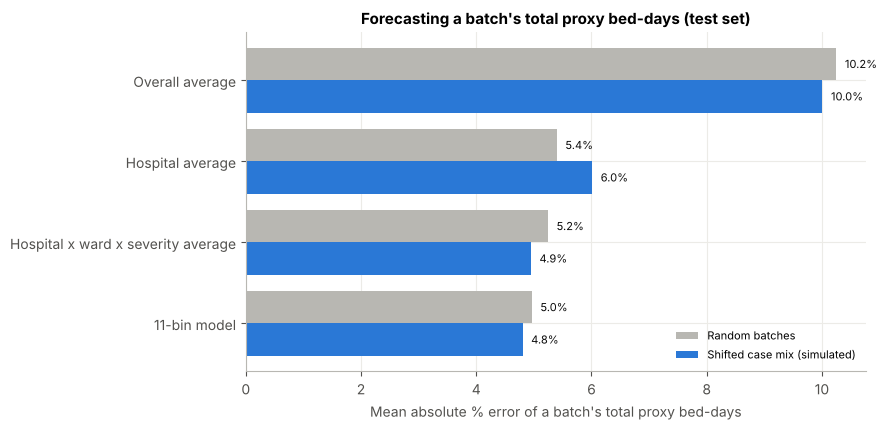

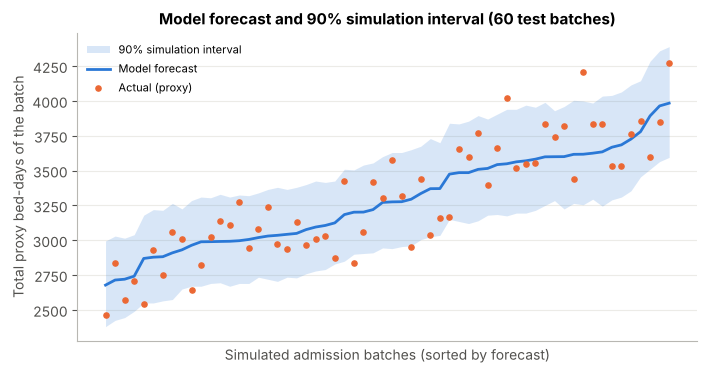

random batches        shifted case mix       
                                           MAPE % bias %           MAPE % bias %
Overall average                             10.25   1.87            10.01  -3.11
Hospital average                             5.40   0.85             6.01  -4.06
Hospital x ward x severity average           5.24   0.80             4.95  -0.29
11-bin model                                 4.96   0.44             4.80  -0.12

In [38]:
shift_weights = (test_df["Severity of Illness"].map({0: 1.0, 1: 2.0, 2: 4.0}).to_numpy()
                 * np.where(test_df["Age"].to_numpy() >= 6, 2.0, 1.0))   # Age band 6 = 61-70
shift_batches = make_batches(test_df, 100, np.random.default_rng(SEED + 2), weights=shift_weights)
shift_table = batch_forecast_table(test_df, ops_forecasts, ops_bin_proba, shift_batches, actual_days,
                                   SETTINGS["mc_draws"], np.random.default_rng(SEED + 3))
shift_summary, shift_coverage = summarise_batches(shift_table, METHODS)
print("Shifted case mix: mean actual batch total %.0f vs %.0f in normal batches"
      % (shift_table["actual"].mean(), normal_table["actual"].mean()))
print("Model 90%% interval coverage: %.1f%%" % (shift_coverage * 100))

fig = plotting.batch_errors(METHODS, [normal_summary["MAPE %"].values / 100, shift_summary["MAPE %"].values / 100],
                            ["Random batches", "Shifted case mix (simulated)"],
                            "Forecasting a batch's total proxy bed-days (test set)")
plotting.save_show(fig, "09_batch_forecast_error")
sample = normal_table.sample(min(60, len(normal_table)), random_state=SEED)
fig = plotting.batch_intervals(sample["11-bin model"].values, sample["p05"].values, sample["p95"].values,
                               sample["actual"].values, "Model forecast and 90% simulation interval (60 test batches)")
plotting.save_show(fig, "10_batch_intervals")

ops_summary = pd.concat({"random batches": normal_summary, "shifted case mix": shift_summary}, axis=1)
save_table(ops_summary.round(2), "batch_forecast_summary")
RESULTS["batches"] = {
    "n_test_batches": int(len(normal_table)), "batch_size": 100,
    "random": normal_summary.round(3).to_dict(orient="index"), "random_coverage": round(normal_coverage, 4),
    "shifted": shift_summary.round(3).to_dict(orient="index"), "shifted_coverage": round(shift_coverage, 4),
    "mean_actual_random": round(float(normal_table["actual"].mean()), 1),
    "mean_actual_shifted": round(float(shift_table["actual"].mean()), 1),
}
ops_summary.round(2)

**How to read this.** In the shifted scenario the average batch needs more bed-days (3,366 vs 3,203). The plain hospital average then under-forecasts (-4.1% bias) and its error rises to 6.0%. The hospital × ward × severity table and the model both account for severity and stay accurate (4.9% and 4.8%), with interval coverage 91.8%. Taking the case mix into account matters more than the choice between a lookup table and a model.

### 11.4 Sensitivity to the proxy-day assumption

Bed-days rely on the bin midpoint and on 110 days for ">100 days". We recompute the batch comparison with other mappings: a longer tail (150 days for ">100"), the lower edge of each bin, and the upper edge (with 150 for ">100"). Both the actual totals and the forecasts use the same mapping, and the same predicted probabilities and batches are reused.

In [39]:
DAY_MAPPINGS = {
    "midpoint, >100 = 110 (main)": PROXY_DAYS,
    "midpoint, >100 = 150": np.array([5, 15, 25, 35, 45, 55, 65, 75, 85, 95, 150], dtype=float),
    "lower edge (0, 11, ..., 101)": np.array([0, 11, 21, 31, 41, 51, 61, 71, 81, 91, 101], dtype=float),
    "upper edge (10, ..., 100, >100 = 150)": np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 150], dtype=float),
}
sens_rows = []
for label, mapping in DAY_MAPPINGS.items():
    train_days = mapping[y_train_bin]
    tr = train_df.assign(days_alt=train_days)
    actual_alt = mapping[y_test_bin]
    forecasts_alt = {
        "Hospital x ward x severity average": lookup_mean_days(tr, test_df, LOOKUP_KEYS, days_col="days_alt"),
        "11-bin model": ops_bin_proba @ mapping,
    }
    row = {"mapping": label, "mean actual batch total": np.mean([actual_alt[b].sum() for b in normal_batches])}
    for name, est in forecasts_alt.items():
        errs = [abs(est[b].sum() - actual_alt[b].sum()) / actual_alt[b].sum() for b in normal_batches]
        row[name + " MAPE %"] = np.mean(errs) * 100
    sens_rows.append(row)
sensitivity = pd.DataFrame(sens_rows).set_index("mapping")
save_table(sensitivity.round(2), "proxy_day_sensitivity")
RESULTS["proxy_sensitivity"] = sensitivity.round(2).to_dict(orient="index")
sensitivity.round(2)

,mean actual batch total,Hospital x ward x severity average MAPE %,11-bin model MAPE %
mapping,,,
"midpoint, >100 = 110 (main)",3203.32,5.24,4.96
"midpoint, >100 = 150",3287.70,5.93,5.63
"lower edge (0, 11, ..., 101)",2785.46,5.99,5.66
"upper edge (10, ..., 100, >100 = 150)",3777.15,5.04,4.79


**How to read this.** The totals themselves change with the assumption (mean batch total 2,785-3,777 proxy bed-days), which is why absolute bed-day numbers should be read as approximate. The comparison is stable: under every mapping the model's error (4.8-5.7%) stays below the lookup table's (5.0-6.0%).

### 11.5 Screening admissions for likely long stays

Suppose a discharge-planning team can review only a fixed share of new admissions. We rank the test admissions by P(Long) from the final 3-class model and flag the top 10%, 20% or 30%. For comparison, we rank by the Long share of the hospital × ward × severity group in the training data, and by random order. We report recall (share of all actual Long stays that are flagged), precision (share of flagged admissions that are actually Long), lift (precision divided by the overall Long share), and the share of all proxy bed-days that the flagged admissions account for.

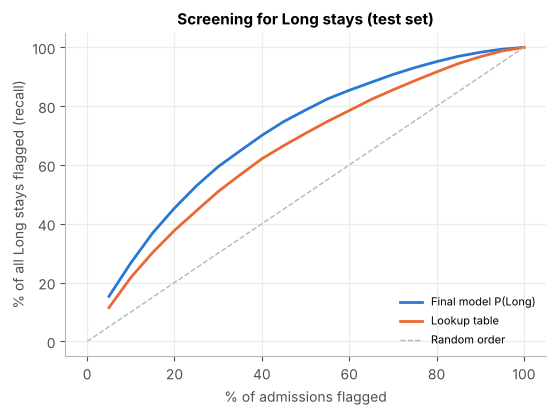

recall %  precision %  lift  % of proxy bed-days
flagged share ranking                                                            
10%           Final model            26.7         51.5   2.7                 15.6
              Lookup table           21.7         42.0   2.2                 13.7
              Random (expected)      10.0         19.3   1.0                 10.0
20%           Final model            45.3         43.7   2.3                 28.4
              Lookup table           37.7         36.4   1.9                 25.7
              Random (expected)      20.0         19.3   1.0                 20.0
30%           Final model            59.4         38.2   2.0                 39.7
              Lookup table           51.0         32.8   1.7                 36.9
              Random (expected)      30.0         19.3   1.0                 30.0

In [40]:
def screening(p_long, frame, share):
    """Flag the top `share` of admissions by p_long and describe the flagged group."""
    n_flag = int(round(share * len(frame)))
    flagged = np.zeros(len(frame), dtype=bool)
    flagged[np.argsort(-p_long, kind="stable")[:n_flag]] = True
    is_long = frame["is_long"].to_numpy() == 1
    days = frame["proxy_days"].to_numpy()
    precision_ = is_long[flagged].mean()
    return {"recall": is_long[flagged].sum() / is_long.sum(), "precision": precision_,
            "lift": precision_ / is_long.mean(), "share_of_proxy_bed_days": days[flagged].sum() / days.sum()}


p_long_lookup = lookup_table_probabilities(train_df, test_df, LOOKUP_KEYS)[:, 2]
screen_rows = []
for share in [0.10, 0.20, 0.30]:
    for label, p in [("Final model", p_long_final), ("Lookup table", p_long_lookup)]:
        r = screening(p, test_df, share)
        r.update({"flagged share": "%d%%" % (share * 100), "ranking": label})
        screen_rows.append(r)
    screen_rows.append({"flagged share": "%d%%" % (share * 100), "ranking": "Random (expected)", "recall": share,
                        "precision": test_df["is_long"].mean(), "lift": 1.0, "share_of_proxy_bed_days": share})
screening_table = pd.DataFrame(screen_rows).set_index(["flagged share", "ranking"])
save_table(screening_table.round(4), "long_stay_screening")
RESULTS["screening"] = {"%s | %s" % k: {m: round(float(v), 4) for m, v in row.items()}
                        for k, row in screening_table.iterrows()}

fractions = np.linspace(0.05, 1.0, 20)
curves = {"Final model P(Long)": [screening(p_long_final, test_df, f)["recall"] for f in fractions],
          "Lookup table": [screening(p_long_lookup, test_df, f)["recall"] for f in fractions]}
fig = plotting.screening_curves(fractions, curves, "Screening for Long stays (test set)")
plotting.save_show(fig, "11_long_stay_screening")
(screening_table * [100, 100, 1, 100]).round(1).rename(columns={"recall": "recall %", "precision": "precision %",
                                                              "share_of_proxy_bed_days": "% of proxy bed-days"})

**How to read this.** If 20% of admissions are flagged, the list contains **45.3%** of all eventual Long stays (lookup table 37.7%, random 20%), and 43.7% of the flagged admissions are Long (lift 2.3). Together they account for 28.4% of all proxy bed-days. With a 10% list the model captures 26.7%, with 30% it captures 59.4%. This shows **identification**, nothing more: whether reviewing these patients early would shorten their stays or save money is a separate question that would need a prospective trial.

## 12. Conclusions, business implications and limitations

In [41]:
# Key numbers of this run, printed from the stored results
final_row = test_table.loc[FINAL_NAME]
print("Final model:", FINAL_NAME)
print("  test accuracy %.1f%% (95%% CI %.1f-%.1f), macro-F1 %.1f%% (95%% CI %.1f-%.1f)"
      % (final_row["accuracy"] * 100, final_row["accuracy_ci_low"] * 100, final_row["accuracy_ci_high"] * 100,
         final_row["macro_f1"] * 100, final_row["macro_f1_ci_low"] * 100, final_row["macro_f1_ci_high"] * 100))
print("  lookup table: accuracy %.1f%%, macro-F1 %.1f%% | majority class: accuracy %.1f%%"
      % (test_table.loc["Lookup table", "accuracy"] * 100, test_table.loc["Lookup table", "macro_f1"] * 100,
         test_table.loc["Majority class", "accuracy"] * 100))
print("  P(Long) ROC-AUC %.3f" % ranking_table.loc[FINAL_NAME, "roc_auc_long"])
s20 = screening_table.loc[("20%", "Final model")]
s20b = screening_table.loc[("20%", "Lookup table")]
print("  flag top 20%%: recall of Long stays %.1f%% (lookup table %.1f%%)" % (s20["recall"] * 100, s20b["recall"] * 100))
print("  batch bed-day MAPE: model %.1f%% vs best average %.1f%% (random batches)"
      % (normal_summary.loc["11-bin model", "MAPE %"], normal_summary.loc["Hospital x ward x severity average", "MAPE %"]))

RESULTS["runtime_seconds"] = round(time.time() - RUN_START, 1)
RESULTS["environment"] = {"python": platform.python_version(), "pandas": pd.__version__,
                          "scikit_learn": sklearn.__version__, "numpy": np.__version__,
                          "matplotlib": matplotlib.__version__}
with open(RESULTS_DIR / "metrics.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("\nSaved", RESULTS_DIR / "metrics.json", "| run time %.0f s" % RESULTS["runtime_seconds"])

Final model: Gradient boosting (leaves=63, min_leaf=200)
  test accuracy 54.1% (95% CI 53.7-54.5), macro-F1 48.5% (95% CI 48.0-48.9)
  lookup table: accuracy 50.6%, macro-F1 38.4% | majority class: accuracy 48.7%
  P(Long) ROC-AUC 0.752
  flag top 20%: recall of Long stays 45.3% (lookup table 37.7%)
  batch bed-day MAPE: model 5.0% vs best average 5.2% (random batches)

Saved /home/claude/v2/results/metrics.json | run time 531 s


### Answers to the research questions

1. **Prediction.** Using only admission-time information, the selected gradient boosting model classifies unseen patients with 54.1% accuracy and 48.5% macro-F1. That is clearly better than the lookup table (50.6% / 38.4%) and the majority rule (48.7% / 21.8%), and slightly better than the random forest (53.5% / 47.0%). The gain is real but modest; most errors confuse neighbouring classes, and Short and Long stays are often predicted as Medium.
2. **Drivers.** The hospital and the ward type matter most, followed by the deposit in combination with them, the patient's city, the admission type, the severity and the bed grade. `Visitors with Patient` would add 8.6 accuracy points, but only if it is known at admission.
3. **Operational use (simulated).** As a risk *ranking*, the model is clearly useful: a 20% review list captures 45.3% of Long stays, against 37.7% for the lookup table, and its P(Long) matches observed rates on the test set. For the cumulative bed-days of 100-admission batches it improves only a little on case-mix-aware averages (5.0% vs 5.2%), and its 90% range was reliable in the simulation (91.1% coverage).

### Business implications

* **What the experiment found:** admission data rank long-stay risk well but predict individual LOS only modestly; group-level bed-day demand is already well estimated by case-mix-aware averages.
* **Actions a manager could consider:** use the risk ranking to choose which admissions a discharge-planning team reviews first; use group forecasts with their range as one planning input; find out when visitors and the other fields are recorded.
* **What must be validated before real use:** the timing of each input; performance on later periods and other hospitals; daily occupancy with real admission dates; and, with a prospective study, whether early review actually shortens stays or frees beds.

### Limitations

* Availability at admission is assumed for several fields; the data cannot confirm it.
* LOS is binned, and bed-days use proxy midpoints (110 days for ">100").
* There are no dates: no validation over time, no daily occupancy, no true patient history.
* The model search was deliberately small; a larger search might add a little.
* One dataset with a random patient split; results may differ for other hospitals or later years.

The full discussion is in [`../FINAL_REPORT.md`](../FINAL_REPORT.md); the comparison with the original project is in [`../PROJECT_EVOLUTION.md`](../PROJECT_EVOLUTION.md).